In [ ]:
# ── 재현성: 버전을 먼저 박아둔다. 세션 간 EM 불일치의 1순위 용의자 ──
!pip install -q "transformers==4.44.2" "accelerate>=0.33" "torch" 2>&1 | tail -1

from google.colab import drive
drive.mount('/content/drive')

import os, re, json, string, gc, random
import numpy as np, pandas as pd, torch
from tqdm.auto import tqdm

import transformers
print("transformers:", transformers.__version__)
print("torch:", torch.__version__, "| GPU:", torch.cuda.get_device_name(0))

ERROR: ERROR: Failed to build installable wheels for some pyproject.toml based projects (tokenizers)
Mounted at /content/drive
transformers: 5.16.1
torch: 2.11.0+cu128 | GPU: NVIDIA A100-SXM4-40GB


In [ ]:
SEED      = 42
MAX_NEW   = 48          # 16토큰에서 결론이 뒤집힌 전례가 있어 48 고정
BS        = 16
MODEL_ID  = "NousResearch/Meta-Llama-3.1-8B-Instruct"

P9    = "/content/drive/MyDrive/Grad_share/data_share/P9"
P6    = "/content/drive/MyDrive/Grad_share/data_share/P6"
OUT   = "/content/drive/MyDrive/Grad_share/data_share/P9/T456"
os.makedirs(OUT, exist_ok=True)

BLOCKS = {"front": [8,9,10,11,12], "signal": [14,15,16,17,18]}   # 훅 인덱스(0-based)
SEEDS  = [0, 1, 2]

np.random.seed(SEED); random.seed(SEED); torch.manual_seed(SEED)

In [ ]:
pairs = pd.read_csv(f"{P9}/p8s_behavior.csv")
HID   = np.load(f"{P9}/hid_p8s.npy")                       # (1224, 32*4096)
ids   = np.load(f"{P9}/hid_p8s_ids.npy", allow_pickle=True)

# 행 정렬 검증 — 이게 깨지면 w가 엉뚱한 샘플에서 나옴
assert (pairs["question"].values == ids).all(), "★ HID와 pairs 행 정렬 불일치"
assert HID.shape == (len(pairs), 32*4096), f"★ HID shape {HID.shape}"

print(pairs.shape, HID.shape)
print(pairs.groupby(["kside","ctx_label"]).size().unstack(fill_value=0))
print("behavior:", pairs.behavior.value_counts().to_dict())
print("컬럼:", list(pairs.columns))

(1224, 19) (1224, 131072)
ctx_label   C+   C-
kside              
K+         378  378
K−         234  234
behavior: {'accept': 880, 'retain': 201, 'other': 142, 'abstain': 1}
컬럼: ['question', 'gold', 'prop', 'kside', 'knows', 'A_cb', 'ctx_id', 'ctx_title', 's_wiki_title', 'orig_gold', 'ctx_label', 'ctx_text', 'answer_surface', 'ans_start', 'ans_end', 'wrong_answer', 'answer', 'behavior', 'final_correct']


In [ ]:
def cell(k, c):
    return pairs[(pairs.kside==k) & (pairs.ctx_label==c)].copy()

EVAL = {
    "KpCm": cell("K+","C-"),   # 378  retain 방향  ← T5 (이미 측정됨, 재현용)
    "KpCp": cell("K+","C+"),   # 378  retain 개입이 정답을 훼손하는가  ← T4
    "KmCp": cell("K−","C+"),   # 234  accept 방향 (기측정)
    "KmCm": cell("K−","C-"),   # 234  accept 개입이 틀린 문맥을 더 따르게 하는가 ← T4
}
for k,v in EVAL.items():
    print(f"{k}: n={len(v)}  behavior={v.behavior.value_counts().to_dict()}")

KpCm: n=378  behavior={'accept': 224, 'retain': 105, 'other': 48, 'abstain': 1}
KpCp: n=378  behavior={'accept': 288, 'retain': 60, 'other': 30}
KmCp: n=234  behavior={'accept': 180, 'other': 31, 'retain': 23}
KmCm: n=234  behavior={'accept': 188, 'other': 33, 'retain': 13}


In [ ]:
# K−/C− 전용 보조 지표: 문맥의 틀린 주장을 따라갔는가
print(EVAL["KmCm"][["question","gold","answer_surface","wrong_answer"]].head(3).to_string())

                                                question                                                                                       gold    answer_surface      wrong_answer
990               What is the religion of Thomas Cooray?  ["Catholic Church", "Roman Catholic Church", "Church", "Roman Apostolic Catholic Church"]  Louisiana Voodoo  Louisiana Voodoo
991  What is the capital of Nyandeni Local Municipality?                                                                                 ["Libode"]           Raleigh           Raleigh
992            Who is the author of Fail-Safe Investing?                                                     ["Harry Browne", "Harry Edson Browne"]   Maarten 't Hart   Maarten 't Hart


In [ ]:
sv = pd.read_parquet(f"{P6}/strat_v2_behavior.parquet")
print(sv.shape)
print(sv.dataset_id.value_counts().to_dict())

need = ["dataset_id","question","cb_generation","open_book_gen",
        "parametric_answer","contextual_answer","K_state3","behavior"]
missing = [c for c in need if c not in sv.columns]
print("누락 컬럼:", missing)          # [] 이어야 T7이 생성 없이 돌아감
print(sv[need].head(2).to_string())

(1916, 43)
{'clasheval': 480, 'confiqa_qa': 480, 'dynamicqa': 479, 'nqswap': 477}
누락 컬럼: []
  dataset_id                                                                                       question cb_generation                                                                                                                                open_book_gen parametric_answer contextual_answer K_state3 behavior
0  clasheval                                      What year was Phil Knight's memoir, 'Shoe Dog', released?          2016  The year Phil Knight's memoir, 'Shoe Dog', was released is actually incorrect in the given text. The correct year should be 2016, not 1961.              2016              1961       K+     both
1  clasheval  Which year was the USS Missouri (BB-63), an Iowa-class battleship, commissioned into service?          1944                                         The USS Missouri (BB-63), an Iowa-class battleship, was commissioned into service in 1944, not 1977.            

In [ ]:
## Cell 5 — 공통 유틸
# ── 정규화/매칭: P9 세 노트북 공통. 그대로 유지 ──
def normalize(s):
    s = str(s).lower()
    s = re.sub(r"\b(a|an|the)\b", " ", s)
    s = "".join(ch for ch in s if ch not in string.punctuation)
    return " ".join(s.split())

def match_gold(text, golds):
    t = normalize(text)
    for g in golds:
        if not str(g).strip(): continue
        if re.search(r"\b"+re.escape(normalize(g))+r"\b", t): return True
    return False

def as_list(g):                       # gold가 '["a","b"]' 문자열인 경우 대응
    return json.loads(g) if str(g).startswith("[") else [g]

def em(ans, gold):
    return int(match_gold(ans, as_list(gold)))

REFUSAL_PAT = re.compile(
    r"(i (don'?t|do not) know|couldn'?t find|cannot|unable to|no information|not sure)",
    re.IGNORECASE)

REFUSAL_EXT = re.compile(
    r"(i (don'?t|do not) know|couldn'?t find|cannot|unable to|no information|not sure"
    r"|does ?n[o']?t (mention|state|specify|provide|explicitly)"
    r"|no mention of|not (mentioned|specified|stated) in)", re.IGNORECASE)

# 붕괴 판정: P9_steering_val cell 74 원본(greedy). 보고서 "붕괴율 0.00"의 기준
def collapsed(t):
    t = str(t); w = t.split()
    if len(w) >= 8 and len(set(w))/len(w) < 0.3: return True
    return re.search(r"(.{2,10})\1{3,}", t) is not None

# ── hidden / w ──
def layer(H, L): return H[:, (L-1)*4096:L*4096]      # L: 1~32

def diff_of_means(H, mask_a, mask_b):
    Wm = np.zeros((32, 4096), dtype=np.float32)
    for L in range(1, 33):
        HL = layer(H, L)
        d = HL[mask_a].mean(0) - HL[mask_b].mean(0)
        Wm[L-1] = d / (np.linalg.norm(d) + 1e-8)
    return Wm

def cos_layers(A, B):
    return np.array([np.dot(A[l],B[l])/((np.linalg.norm(A[l])*np.linalg.norm(B[l]))+1e-8)
                     for l in range(32)])

In [ ]:
## Cell 6 — σ 3종 동시 산출
Hk = HID[EVAL["KpCm"].index.values]                      # K+/C− 378행
sigma = np.array([layer(Hk, L).std() for L in range(1,33)], dtype=np.float32)  # 현재 정의

# 참고용 3종 비교 (w는 아직 없으니 임시로 기존 w_main 사용)
W_ref = np.load(f"{P9}/w_directions.npz")["w_main"].astype(np.float32)
rows = []
for L in [9,11,13,15,17,19]:
    HL = layer(Hk, L)
    g = float(HL.std())                    # grand std  ← 현재 사용 중
    wi = float(HL.std(axis=0).mean())      # within-dim std (차원별 std의 평균)
    pj = float((HL @ W_ref[L-1]).std())    # projection std (세령 라인 정의)
    rows.append((L, g, wi, pj, g/wi, pj/wi))
print(pd.DataFrame(rows, columns=["L","grand","within","proj","grand/within","proj/within"]
                  ).round(4).to_string(index=False))

print("\nsignal σ:", sigma[[14,15,16,17,18]].round(4))
print("front  σ:", sigma[[8,9,10,11,12]].round(4))
print("※ 이 노트북 coef는 grand-std 기준. 세령 라인(projection std)과 직접 비교 불가.")

 L  grand  within   proj  grand/within  proj/within
 9 0.0718  0.0193 0.2514        3.7213      13.0249
11 0.0817  0.0273 0.4499        2.9923      16.4724
13 0.0992  0.0334 0.5702        2.9693      17.0710
15 0.1168  0.0439 0.7445        2.6578      16.9396
17 0.1541  0.0669 1.2107        2.3027      18.0933
19 0.1909  0.0880 1.4951        2.1682      16.9846

signal σ: [0.1168 0.1322 0.1541 0.1723 0.1909]
front  σ: [0.0718 0.0775 0.0817 0.088  0.0992]
※ 이 노트북 coef는 grand-std 기준. 세령 라인(projection std)과 직접 비교 불가.


In [ ]:
## Cell 7 — 라벨러 (both 3-way)
COLMAP = {
    "p8s": dict(gen="answer",        ctx_ans="answer_surface",
                cb="A_cb",           param_ans="gold"),
    "sv" : dict(gen="open_book_gen", ctx_ans="contextual_answer",
                cb="cb_generation",  param_ans="parametric_answer"),
}

def lab_sf3(row, m, refusal=REFUSAL_PAT):
    """both를 accept에 흡수시키지 않고 별도 범주로 남긴다."""
    ans = str(row[m["gen"]])
    if refusal.search(ans): return "abstain"
    hit_c = match_gold(ans, [row[m["ctx_ans"]]])
    hit_p = match_gold(ans, [row[m["cb"]]])
    if hit_c and hit_p: return "both"
    if hit_c:           return "accept"
    if hit_p:           return "retain"
    return "other"

def to_group(lab, both_as="retain"):
    """both_as: 'retain' | 'accept' | 'exclude'  ← 실험 변수"""
    if lab == "both":
        return {"retain":"retain", "accept":"accept", "exclude":"other"}[both_as]
    return lab

In [ ]:
## Cell 8 — p8s both 감사 ★결정 셀
m = COLMAP["p8s"]
pairs["sf3"] = pairs.apply(lambda r: lab_sf3(r, m), axis=1)

print("=== 전체 sf3 분포 ===")
print(pairs.sf3.value_counts().to_dict())

print("\n=== 기존 gold behavior × sf3 ===")
print(pd.crosstab(pairs.behavior, pairs.sf3))

print("\n=== 셀별 sf3 ===")
print(pairs.groupby(["kside","ctx_label"]).sf3.value_counts().unstack(fill_value=0))

kpcm = pairs[(pairs.kside=="K+")&(pairs.ctx_label=="C-")]
nb = (kpcm.sf3=="both").sum()
print(f"\n★ K+/C− both 개수: {nb} / 378")

print("\n=== both 실제 출력 8개 (눈으로 판정) ===")
for _, r in kpcm[kpcm.sf3=="both"].head(8).iterrows():
    print(f" ctx주장:{str(r.answer_surface)[:22]:22} | cb답:{str(r.A_cb)[:22]:22}")
    print(f"  → {str(r.answer)[:120]}\n")

=== 전체 sf3 분포 ===
{'accept': 607, 'both': 273, 'other': 235, 'retain': 108, 'abstain': 1}

=== 기존 gold behavior × sf3 ===
sf3       abstain  accept  both  other  retain
behavior                                      
abstain         1       0     0      0       0
accept          0     607   273      0       0
other           0       0     0    138       4
retain          0       0     0     97     104

=== 셀별 sf3 ===
sf3              abstain  accept  both  other  retain
kside ctx_label                                      
K+    C+               0      71   217     65      25
      C-               1     170    54     74      79
K−    C+               0     179     1     52       2
      C-               0     187     1     44       2

★ K+/C− both 개수: 54 / 378

=== both 실제 출력 8개 (눈으로 판정) ===
 ctx주장:Paris                  | cb답:Vimmerby.             
  → The text does not mention Vimmerby Municipality or its capital. It talks about Paris Municipality in Kalmar County, Swed

 ctx주장:Frede

In [ ]:
## Cell 9 — both 성격 검증 (CPU, 10초)
def same_answer(row, m):
    """문맥 주장과 closed-book 답이 사실상 같은 답인가"""
    a, b = str(row[m["ctx_ans"]]), str(row[m["cb"]])
    return int(match_gold(a, [b]) or match_gold(b, [a]))

m = COLMAP["p8s"]
pairs["ctx_eq_cb"] = pairs.apply(lambda r: same_answer(r, m), axis=1)

print("=== 셀별 ctx주장 == cb답 비율 ===")
print(pairs.groupby(["kside","ctx_label"]).ctx_eq_cb.mean().round(3))

print("\n=== both 중 ctx==cb (허수 both) 비율 ===")
b = pairs[pairs.sf3=="both"]
print(b.groupby(["kside","ctx_label"]).ctx_eq_cb.agg(["mean","size"]).round(3))

# K+/C− both 54개가 진짜 정정형인지: 부정 표현 동반율
NEG = re.compile(r"\b(not|isn'?t|does ?n'?t|incorrect|mistake|error|actually|however)\b", re.I)
kpcm = pairs[(pairs.kside=="K+")&(pairs.ctx_label=="C-")]
for lab in ["both","accept","retain"]:
    s = kpcm[kpcm.sf3==lab]
    print(f"{lab:8} n={len(s):3}  부정/정정 표현 포함률 {s.answer.apply(lambda a: bool(NEG.search(str(a)))).mean():.3f}")

=== 셀별 ctx주장 == cb답 비율 ===
kside  ctx_label
K+     C+           0.878
       C-           0.000
K−     C+           0.000
       C-           0.000
Name: ctx_eq_cb, dtype: float64

=== both 중 ctx==cb (허수 both) 비율 ===
                  mean  size
kside ctx_label             
K+    C+         0.995   217
      C-         0.000    54
K−    C+         0.000     1
      C-         0.000     1
both     n= 54  부정/정정 표현 포함률 0.981
accept   n=170  부정/정정 표현 포함률 0.394
retain   n= 79  부정/정정 표현 포함률 0.418


In [ ]:
## Cell 10 — w 두 벌 만들고 비교 (CPU, 1분)
kpcm_idx = pairs[(pairs.kside=="K+")&(pairs.ctx_label=="C-")].index.values

def build_w(both_as, idx=kpcm_idx):
    lab = pairs.loc[idx, "sf3"].map(lambda l: to_group(l, both_as)).values
    keep = np.isin(lab, ["accept","retain"])
    gi = idx[keep]; lb = lab[keep]
    w = diff_of_means(HID[gi], lb=="accept", lb=="retain")
    return w, (lb=="accept").sum(), (lb=="retain").sum()

W = {}
for ba in ["accept","retain","exclude"]:
    W[ba], na_, nr_ = build_w(ba)
    print(f"both→{ba:8}  accept n={na_:3}  retain n={nr_:3}")

print("\n=== w 간 코사인 (층별) ===")
for a,b in [("accept","retain"),("accept","exclude"),("retain","exclude")]:
    c = cos_layers(W[a], W[b])
    print(f"{a:8}vs{b:8}", {f"L{L}": round(float(c[L-1]),3) for L in [9,11,15,17,19]})

# 기존 w_main과의 비교 (기존 = gold 라벨 + both가 accept에 흡수된 상태)
W_ref = np.load(f"{P9}/w_directions.npz")["w_main"].astype(np.float32)
for ba in ["accept","retain"]:
    c = cos_layers(W_ref, W[ba])
    print(f"w_main vs both→{ba:8}", {f"L{L}": round(float(c[L-1]),3) for L in [9,11,15,17,19]})

np.savez(f"{OUT}/w_bothpolicy.npz", **{f"both_{k}":v for k,v in W.items()})

both→accept    accept n=224  retain n= 79
both→retain    accept n=170  retain n=133
both→exclude   accept n=170  retain n= 79

=== w 간 코사인 (층별) ===
accept  vsretain   {'L9': 0.799, 'L11': 0.839, 'L15': 0.819, 'L17': 0.776, 'L19': 0.771}
accept  vsexclude  {'L9': 0.979, 'L11': 0.983, 'L15': 0.973, 'L17': 0.965, 'L19': 0.961}
retain  vsexclude  {'L9': 0.905, 'L11': 0.924, 'L15': 0.929, 'L17': 0.915, 'L19': 0.917}
w_main vs both→accept   {'L9': 0.875, 'L11': 0.893, 'L15': 0.922, 'L17': 0.937, 'L19': 0.932}
w_main vs both→retain   {'L9': 0.567, 'L11': 0.619, 'L15': 0.648, 'L17': 0.636, 'L19': 0.626}


In [ ]:
import torch, gc
from transformers import AutoTokenizer, AutoModelForCausalLM

tok = AutoTokenizer.from_pretrained(MODEL_ID)
if tok.pad_token is None: tok.pad_token = tok.eos_token
tok.padding_side = "left"                      # ★ 배치 생성 필수
assert tok.padding_side == "left"

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID, torch_dtype=torch.bfloat16, device_map="auto").eval()

USER_TMPL = "{ctx}\n\nQuestion: {q}\nAnswer:"
def prompt_p8s(row):
    return tok.apply_chat_template(
        [{"role":"user","content":USER_TMPL.format(ctx=row.ctx_text, q=row.question)}],
        add_generation_prompt=True, tokenize=False)

print(repr(prompt_p8s(pairs.iloc[0])[-90:]))

config.json:   0%|          | 0.00/855 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/50.9k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.09M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/296 [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/184 [00:00<?, ?B/s]

'on: What genre is Kanoon?\nAnswer:<|eot_id|><|start_header_id|>assistant<|end_header_id|>\n\n'


In [ ]:
## Cell 12 — 훅 (all/last 두 모드)
sig_t = torch.tensor(sigma, device=model.device, dtype=torch.bfloat16)       # (32,)
w_t   = torch.zeros((32,4096), device=model.device, dtype=torch.bfloat16)    # copy_로 교체

_hooks, _cfg = [], {"coef":0.0, "layers":[], "pos":"all"}

def make_hook(Lidx):
    def hook(mod, inp, out):
        if _cfg["coef"] == 0.0 or Lidx not in _cfg["layers"]:
            return out
        h = out[0] if isinstance(out, tuple) else out
        delta = _cfg["coef"] * sig_t[Lidx] * w_t[Lidx].to(h.dtype)
        if _cfg["pos"] == "all" or h.shape[1] == 1:
            h = h + delta                        # decode는 T=1이라 두 모드가 동일
        else:
            h = h.clone()
            h[:, -1, :] = h[:, -1, :] + delta    # prefill 마지막 토큰만 (left-pad라 -1이 맞음)
        return (h,) + out[1:] if isinstance(out, tuple) else h
    return hook

def attach(layers):
    """★ 32층 전부가 아니라 필요한 층에만. 8/23에 14배 느려졌던 원인"""
    detach()
    for Lidx in layers:
        _hooks.append(model.model.layers[Lidx].register_forward_hook(make_hook(Lidx)))

def detach():
    for h in _hooks: h.remove()
    _hooks.clear()
    for lyr in model.model.layers: lyr._forward_hooks.clear()

In [ ]:
## Cell 13 — 배치 생성기
@torch.no_grad()
def gen_rows(idx, w_row=None, coef=0.0, block=None, pos="all", bs=BS, desc=""):
    if w_row is None or coef == 0.0:
        detach(); _cfg.update(coef=0.0, layers=[], pos=pos)
    else:
        w_t.copy_(torch.tensor(w_row, device=model.device, dtype=torch.bfloat16))
        _cfg.update(coef=coef, layers=list(block), pos=pos)
        attach(block)

    outs = []
    pbar = tqdm(total=len(idx), desc=f"{desc} ({len(idx)}행)", unit="row", leave=False)
    for s in range(0, len(idx), bs):
        chunk = idx[s:s+bs]
        texts = [prompt_p8s(pairs.loc[i]) for i in chunk]
        enc = tok(texts, return_tensors="pt", padding=True,
                  add_special_tokens=False).to(model.device)
        L = enc["input_ids"].shape[1]
        g = model.generate(**enc, max_new_tokens=MAX_NEW, do_sample=False,
                           pad_token_id=tok.pad_token_id)
        outs += [tok.decode(o[L:], **DECODE_KW).strip() for o in g]
        pbar.update(len(chunk))
    pbar.close()
    return outs

In [ ]:
## Cell 14 — 배치화 안전성 검증
idx20 = EVAL["KpCm"].index.values[:20]

single = []
for i in tqdm(idx20, desc="single"):
    enc = tok(prompt_p8s(pairs.loc[i]), return_tensors="pt",
              add_special_tokens=False).to(model.device)
    L = enc["input_ids"].shape[1]
    g = model.generate(**enc, max_new_tokens=MAX_NEW, do_sample=False,
                       pad_token_id=tok.pad_token_id)
    single.append(tok.decode(g[0,L:], skip_special_tokens=True).strip())

batched = gen_rows(idx20, desc="batched")

same = sum(a==b for a,b in zip(single,batched))
em_s = np.mean([em(a, pairs.loc[i].gold) for i,a in zip(idx20,single)])
em_b = np.mean([em(a, pairs.loc[i].gold) for i,a in zip(idx20,batched)])
print(f"문자열 완전일치 {same}/20 | EM single {em_s:.3f} vs batch {em_b:.3f}")
for a,b in zip(single,batched):
    if a!=b: print("  S:",a[:70],"\n  B:",b[:70],"\n")

single:   0%|          | 0/20 [00:00<?, ?it/s]

[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


batched:   0%|          | 0/2 [00:00<?, ?it/s]

문자열 완전일치 17/20 | EM single 0.350 vs batch 0.400
  S: Unfortunately, the text does not mention the city where Offer Nissim w 
  B: Unfortunately, the text does not mention the city where Offer Nissim w 

  S: Based on the text, Martin Garrix is a music producer and DJ, and his s 
  B: Based on the text, Martin Garrix is a music producer and DJ, and his s 

  S: The question is not asking about the author of "The Prince", but rathe 
  B: The question is not about the author of "The Prince", but rather about 



In [ ]:
## Cell 15 — 디코딩 규약 고정 (재현성)

DECODE_KW = dict(skip_special_tokens=True, clean_up_tokenization_spaces=False)

@torch.no_grad()
def gen_rows(idx, w_row=None, coef=0.0, block=None, pos="all", bs=BS, desc=""):
    """
    idx    : pairs 인덱스 배열
    w_row  : (32,4096) 또는 None(baseline). idx 전체가 같은 w를 공유해야 함
    반환   : 생성 텍스트 리스트 (idx 순서)
    ※ baseline도 반드시 이 함수로 생성할 것. bs를 조건마다 바꾸면 비교 무효.
    """
    if w_row is None or coef == 0.0:
        detach(); _cfg.update(coef=0.0, layers=[], pos=pos)
    else:
        w_t.copy_(torch.tensor(w_row, device=model.device, dtype=torch.bfloat16))
        _cfg.update(coef=coef, layers=list(block), pos=pos)
        attach(block)

    outs = []
    for s in tqdm(range(0, len(idx), bs), desc=desc, leave=False):
        chunk = idx[s:s+bs]
        texts = [prompt_p8s(pairs.loc[i]) for i in chunk]
        enc = tok(texts, return_tensors="pt", padding=True,
                  add_special_tokens=False).to(model.device)
        L = enc["input_ids"].shape[1]
        g = model.generate(**enc, max_new_tokens=MAX_NEW, do_sample=False,
                           pad_token_id=tok.pad_token_id)
        outs += [tok.decode(o[L:], **DECODE_KW).strip() for o in g]
    return outs

print("gen_rows 재정의 완료 | BS =", BS)

gen_rows 재정의 완료 | BS = 16


In [ ]:
## Cell 16 — OOF 분할 생성

def make_splits(idx, seed, k=5):
    """질문 단위 그룹 + RandomState 셔플.
       GroupKFold는 결정적이라 시드를 바꿔도 같은 분할이 나옴 → 3시드가 무의미해짐.
       ConFiQA에서 단일 분할 +20이 3시드에서 −1/+0/+0/+2로 무너진 게 이 문제였음."""
    q = pairs.loc[idx, "question"].values
    uq = np.unique(q)
    rs = np.random.RandomState(seed); rs.shuffle(uq)
    fold_of_q = {qq: i % k for i, qq in enumerate(uq)}
    f = np.array([fold_of_q[x] for x in q])
    return [(idx[f != i], idx[f == i]) for i in range(k)]

# 검증: 같은 질문이 train/test에 갈라지지 않는가 + 시드마다 분할이 다른가
kpcm_idx = EVAL["KpCm"].index.values
for sd in SEEDS:
    sp = make_splits(kpcm_idx, sd)
    leak = sum(len(set(pairs.loc[tr,"question"]) & set(pairs.loc[te,"question"])) for tr,te in sp)
    sizes = [len(te) for _, te in sp]
    print(f"seed {sd}: 누수 {leak} | fold 크기 {sizes}")

s0 = [set(te) for _, te in make_splits(kpcm_idx, 0)]
s1 = [set(te) for _, te in make_splits(kpcm_idx, 1)]
print("seed0 vs seed1 분할 동일?", all(a==b for a,b in zip(s0,s1)), "← False여야 정상")

seed 0: 누수 0 | fold 크기 [76, 76, 76, 75, 75]
seed 1: 누수 0 | fold 크기 [76, 76, 76, 75, 75]
seed 2: 누수 0 | fold 크기 [76, 76, 76, 75, 75]
seed0 vs seed1 분할 동일? False ← False여야 정상


In [ ]:
## Cell 17 — OOF w 추정

def build_oof_w(idx, seed, both_as, k=5):
    """반환: dict{fold: (test_idx, w(32,4096))} + 그룹 크기 로그"""
    out, log = {}, []
    for fi, (tr, te) in enumerate(make_splits(idx, seed, k)):
        lab = pairs.loc[tr, "sf3"].map(lambda l: to_group(l, both_as)).values
        keep = np.isin(lab, ["accept","retain"])
        gi, lb = tr[keep], lab[keep]
        w = diff_of_means(HID[gi], lb=="accept", lb=="retain")
        out[fi] = (te, w)
        log.append((fi, len(te), int((lb=="accept").sum()), int((lb=="retain").sum())))
    return out, pd.DataFrame(log, columns=["fold","n_test","n_acc","n_ret"])

W_T5a = {}
for both_as in ["accept", "retain"]:
    for sd in SEEDS:
        W_T5a[(both_as, sd)], lg = build_oof_w(kpcm_idx, sd, both_as)
        print(f"both→{both_as:7} seed{sd}: acc {lg.n_acc.tolist()} ret {lg.n_ret.tolist()}")

both→accept  seed0: acc [182, 181, 171, 185, 177] ret [63, 64, 67, 58, 64]
both→accept  seed1: acc [177, 181, 183, 180, 175] ret [64, 56, 62, 64, 70]
both→accept  seed2: acc [179, 179, 178, 173, 187] ret [66, 64, 61, 68, 57]
both→retain  seed0: acc [136, 134, 135, 142, 133] ret [109, 111, 103, 101, 108]
both→retain  seed1: acc [135, 136, 143, 136, 130] ret [106, 101, 102, 108, 115]
both→retain  seed2: acc [139, 136, 132, 130, 143] ret [106, 107, 107, 111, 101]


In [ ]:
## Cell 17b — w 추정 안정성: 표본 수가 문제인가 라벨 정의가 문제인가

def split_half_cos(idx, both_as, n_rep=20, seed=0, sub_n=None):
    """같은 라벨 정의로 표본을 반으로 나눠 만든 두 w의 코사인. 노이즈 바닥 측정."""
    lab = pairs.loc[idx, "sf3"].map(lambda l: to_group(l, both_as)).values
    keep = np.isin(lab, ["accept","retain"])
    gi, lb = idx[keep], lab[keep]
    a_all, r_all = gi[lb=="accept"], gi[lb=="retain"]
    rs = np.random.RandomState(seed); cs = []
    for _ in range(n_rep):
        a, r = a_all.copy(), r_all.copy()
        if sub_n is not None:                      # retain을 강제로 축소 (표본 통제)
            r = rs.choice(r, size=min(sub_n, len(r)), replace=False)
        rs.shuffle(a); rs.shuffle(r)
        ha, hr = np.array_split(a,2), np.array_split(r,2)
        w1 = diff_of_means(HID[np.r_[ha[0],hr[0]]],
                           np.r_[np.ones(len(ha[0])),np.zeros(len(hr[0]))].astype(bool),
                           np.r_[np.zeros(len(ha[0])),np.ones(len(hr[0]))].astype(bool))
        w2 = diff_of_means(HID[np.r_[ha[1],hr[1]]],
                           np.r_[np.ones(len(ha[1])),np.zeros(len(hr[1]))].astype(bool),
                           np.r_[np.zeros(len(ha[1])),np.ones(len(hr[1]))].astype(bool))
        cs.append(cos_layers(w1,w2))
    return np.median(np.array(cs), axis=0)

LS = [9, 11, 15, 17, 19]
print(f"{'조건':<28}" + "".join(f"L{L:>7}" for L in LS))
for tag, ba, sub in [("both→accept (ret 79)",      "accept", None),
                     ("both→retain (ret 133)",     "retain", None),
                     ("both→retain, ret 79로 축소","retain", 79)]:
    c = split_half_cos(kpcm_idx, ba, sub_n=sub)
    print(f"{tag:<28}" + "".join(f"{c[L-1]:>8.3f}" for L in LS))

조건                          L      9L     11L     15L     17L     19
both→accept (ret 79)           0.406   0.533   0.621   0.695   0.666
both→retain (ret 133)          0.367   0.475   0.712   0.806   0.809
both→retain, ret 79로 축소        0.214   0.310   0.633   0.729   0.759


In [ ]:
## Cell 17c — T5a용 OOF w (3조건 × 3시드)

def build_oof_w(idx, seed, both_as, ret_cap=None, k=5, cap_seed=0):
    """ret_cap: retain 학습 표본을 이 수로 무작위 축소 (표본 수 통제)"""
    out, log = {}, []
    rs = np.random.RandomState(1000 + seed*10 + cap_seed)
    for fi, (tr, te) in enumerate(make_splits(idx, seed, k)):
        lab  = pairs.loc[tr, "sf3"].map(lambda l: to_group(l, both_as)).values
        keep = np.isin(lab, ["accept","retain"])
        gi, lb = tr[keep], lab[keep]
        a_idx, r_idx = gi[lb=="accept"], gi[lb=="retain"]
        if ret_cap is not None and len(r_idx) > ret_cap:
            r_idx = rs.choice(r_idx, size=ret_cap, replace=False)
        sel = np.r_[a_idx, r_idx]
        m_a = np.r_[np.ones(len(a_idx)), np.zeros(len(r_idx))].astype(bool)
        w = diff_of_means(HID[sel], m_a, ~m_a)
        out[fi] = (te, w)
        log.append((fi, len(te), len(a_idx), len(r_idx)))
    return out, pd.DataFrame(log, columns=["fold","n_test","n_acc","n_ret"])

# fold별 retain을 79의 4/5 ≈ 63으로 맞춘다 (both→accept의 실제 fold 크기와 동일 대역)
CONDS = {
    "both_accept"   : dict(both_as="accept", ret_cap=None),   # ret ~63
    "both_retain"   : dict(both_as="retain", ret_cap=None),   # ret ~106
    "both_ret_n63"  : dict(both_as="retain", ret_cap=63),     # ret =63  ← 통제
}

W_T5a = {}
for cond, kw in CONDS.items():
    for sd in SEEDS:
        W_T5a[(cond, sd)], lg = build_oof_w(kpcm_idx, sd, **kw)
        print(f"{cond:14} seed{sd}: acc {lg.n_acc.tolist()} ret {lg.n_ret.tolist()}")

both_accept    seed0: acc [182, 181, 171, 185, 177] ret [63, 64, 67, 58, 64]
both_accept    seed1: acc [177, 181, 183, 180, 175] ret [64, 56, 62, 64, 70]
both_accept    seed2: acc [179, 179, 178, 173, 187] ret [66, 64, 61, 68, 57]
both_retain    seed0: acc [136, 134, 135, 142, 133] ret [109, 111, 103, 101, 108]
both_retain    seed1: acc [135, 136, 143, 136, 130] ret [106, 101, 102, 108, 115]
both_retain    seed2: acc [139, 136, 132, 130, 143] ret [106, 107, 107, 111, 101]
both_ret_n63   seed0: acc [136, 134, 135, 142, 133] ret [63, 63, 63, 63, 63]
both_ret_n63   seed1: acc [135, 136, 143, 136, 130] ret [63, 63, 63, 63, 63]
both_ret_n63   seed2: acc [139, 136, 132, 130, 143] ret [63, 63, 63, 63, 63]


In [ ]:
## Cell 17c-fix — acc_cap 인자 추가 (지금은 미사용, 나중을 위한 재사용성)

def build_oof_w(idx, seed, both_as, ret_cap=None, acc_cap=None, k=5, cap_seed=0):
    out, log = {}, []
    rs = np.random.RandomState(1000 + seed*10 + cap_seed)
    for fi, (tr, te) in enumerate(make_splits(idx, seed, k)):
        lab  = pairs.loc[tr, "sf3"].map(lambda l: to_group(l, both_as)).values
        keep = np.isin(lab, ["accept","retain"])
        gi, lb = tr[keep], lab[keep]
        a_idx, r_idx = gi[lb=="accept"], gi[lb=="retain"]
        if ret_cap is not None and len(r_idx) > ret_cap:
            r_idx = rs.choice(r_idx, size=ret_cap, replace=False)
        if acc_cap is not None and len(a_idx) > acc_cap:
            a_idx = rs.choice(a_idx, size=acc_cap, replace=False)
        sel = np.r_[a_idx, r_idx]
        m_a = np.r_[np.ones(len(a_idx)), np.zeros(len(r_idx))].astype(bool)
        out[fi] = (te, diff_of_means(HID[sel], m_a, ~m_a))
        log.append((fi, len(te), len(a_idx), len(r_idx)))
    return out, pd.DataFrame(log, columns=["fold","n_test","n_acc","n_ret"])

# W_T5a는 이미 만들어졌으므로 재생성 불필요. 그대로 Cell 18로.
print("acc_cap 인자 추가 완료 (현재 조건에는 미적용)")

acc_cap 인자 추가 완료 (현재 조건에는 미적용)


In [ ]:
## Cell 18 — T5a: both 정책 결정  [A100 ~9분 / L4 ~28분]
## baseline은 이미 완료됐으면 자동 skip

import os
CKPT = f"{OUT}/T5a_generations.parquet"
prev = pd.read_parquet(CKPT) if os.path.exists(CKPT) else pd.DataFrame()
done = set(map(tuple, prev[["cond","seed"]].drop_duplicates().values)) if len(prev) else set()
print("이미 완료:", sorted(done))

def save_rows(cond, seed, idx, outs):
    global prev
    df = pd.DataFrame(dict(cond=cond, seed=seed, row=np.asarray(idx), gen=outs))
    prev = pd.concat([prev, df], ignore_index=True)
    prev.to_parquet(CKPT, index=False)

# baseline (개입 없음 → seed=-1)
if ("baseline", -1) not in done:
    outs = gen_rows(kpcm_idx, desc="baseline")
    save_rows("baseline", -1, kpcm_idx, outs)
    print("baseline EM:", round(float(np.mean([em(a, pairs.loc[i].gold)
                                    for i,a in zip(kpcm_idx,outs)])), 3))

for cond in CONDS:
    for sd in SEEDS:
        if (cond, sd) in done: continue
        idx_all, out_all = [], []
        for fi, (te, w) in W_T5a[(cond, sd)].items():
            o = gen_rows(te, w_row=w, coef=-3, block=BLOCKS["signal"], pos="all",
                         desc=f"{cond}-s{sd}-f{fi}")
            idx_all += list(te); out_all += o
        save_rows(cond, sd, idx_all, out_all)
        e = np.mean([em(a, pairs.loc[i].gold) for i,a in zip(idx_all,out_all)])
        print(f"{cond:14} seed{sd}: EM {e:.3f}")

detach()
print("T5a 완료 →", CKPT)

이미 완료: [('baseline', -1)]


both_accept-s0-f0 (76행):   0%|          | 0/76 [00:00<?, ?row/s]

both_accept-s0-f1 (76행):   0%|          | 0/76 [00:00<?, ?row/s]

both_accept-s0-f2 (76행):   0%|          | 0/76 [00:00<?, ?row/s]

both_accept-s0-f3 (75행):   0%|          | 0/75 [00:00<?, ?row/s]

...

both_ret_n63-s2-f1 (76행):   0%|          | 0/76 [00:00<?, ?row/s]

both_ret_n63-s2-f2 (76행):   0%|          | 0/76 [00:00<?, ?row/s]

both_ret_n63-s2-f3 (75행):   0%|          | 0/75 [00:00<?, ?row/s]

both_ret_n63-s2-f4 (75행):   0%|          | 0/75 [00:00<?, ?row/s]

both_ret_n63   seed2: EM 0.545
T5a 완료 → /content/drive/MyDrive/Grad_share/data_share/P9/T456/T5a_generations.parquet


In [ ]:
## Cell 18-check — baseline 재사용 타당성 확인

b = prev[prev.cond=="baseline"]
print("baseline 행 수:", len(b), "| 기대 378")
bem = np.array([em(g, pairs.loc[i].gold) for i, g in zip(b.row, b.gen)])
print("baseline EM:", round(bem.mean(), 3), "| 틀린 것:", int((bem==0).sum()))
print("붕괴율:", round(float(np.mean([collapsed(g) for g in b.gen])), 3))
print("\n샘플 3개:")
for g in b.gen.head(3): print("  ", g[:90])

baseline 행 수: 378 | 기대 378
baseline EM: 0.471 | 틀린 것: 200
붕괴율: 0.003

샘플 3개:
   Action
   The authors of "Free to Choose: A Personal Statement" are Milton and Rose D. Friedman.
   The Busia District.


In [ ]:
## Cell 19 — T5a 분석: 순증 CI와 조건 간 짝지은 대비

def cluster_bootstrap(base, cur, groups, n_boot=2000, seed=0):
    """질문 단위 리샘플. 반환: 순증 점추정과 95% CI"""
    uq = np.unique(groups)
    idx_of = {q: np.where(groups==q)[0] for q in uq}
    rs = np.random.RandomState(seed); nets=[]
    for _ in range(n_boot):
        pick = rs.choice(uq, size=len(uq), replace=True)
        sel  = np.concatenate([idx_of[q] for q in pick])
        b, c = base[sel], cur[sel]
        nets.append(((b==0)&(c==1)).sum() - ((b==1)&(c==0)).sum())
    net = ((base==0)&(cur==1)).sum() - ((base==1)&(cur==0)).sum()
    return net, np.percentile(nets, [2.5, 97.5])

# 조건별 EM 벡터를 baseline의 행 순서에 맞춰 정렬
b   = prev[prev.cond=="baseline"].set_index("row")
rows = b.index.values
gset = pairs.loc[rows, "question"].values
base = np.array([em(b.loc[i,"gen"], pairs.loc[i].gold) for i in rows])

VEC = {"baseline": base}
for cond in CONDS:
    for sd in SEEDS:
        d = prev[(prev.cond==cond)&(prev.seed==sd)].set_index("row")
        VEC[(cond,sd)] = np.array([em(d.loc[i,"gen"], pairs.loc[i].gold) for i in rows])

print("=== 조건별 순증 (baseline 대비) ===")
print(f"{'조건':<16}{'seed':>5}{'EM':>7}{'회복':>6}{'손상':>6}{'순증':>7}  95% CI")
for cond in CONDS:
    for sd in SEEDS:
        c = VEC[(cond,sd)]
        rec = int(((base==0)&(c==1)).sum()); brk = int(((base==1)&(c==0)).sum())
        net, ci = cluster_bootstrap(base, c, gset)
        print(f"{cond:<16}{sd:>5}{c.mean():>7.3f}{rec:>6}{brk:>6}{net:>+7}  [{ci[0]:+.0f}, {ci[1]:+.0f}]")

=== 조건별 순증 (baseline 대비) ===
조건               seed     EM    회복    손상     순증  95% CI
both_accept         0  0.540    44    18    +26  [+11, +41]
both_accept         1  0.508    40    26    +14  [-2, +30]
both_accept         2  0.526    46    25    +21  [+5, +37]
both_retain         0  0.542    53    26    +27  [+10, +44]
both_retain         1  0.563    58    23    +35  [+19, +52]
both_retain         2  0.537    51    26    +25  [+9, +42]
both_ret_n63        0  0.548    54    25    +29  [+12, +46]
both_ret_n63        1  0.529    47    25    +22  [+7, +39]
both_ret_n63        2  0.545    52    24    +28  [+11, +45]


In [ ]:
## Cell 20 — 조건 간 직접 대비 (동일 378행이므로 차이를 직접 부트스트랩)

def paired_diff(base, cA, cB, groups, n_boot=2000, seed=0):
    """조건 A와 B의 순증 차이. CI가 0을 포함하면 구별불가"""
    uq = np.unique(groups); idx_of = {q: np.where(groups==q)[0] for q in uq}
    rs = np.random.RandomState(seed); ds=[]
    def net(bb, cc): return ((bb==0)&(cc==1)).sum() - ((bb==1)&(cc==0)).sum()
    for _ in range(n_boot):
        pick = rs.choice(uq, size=len(uq), replace=True)
        sel  = np.concatenate([idx_of[q] for q in pick])
        ds.append(net(base[sel], cA[sel]) - net(base[sel], cB[sel]))
    return net(base,cA)-net(base,cB), np.percentile(ds,[2.5,97.5])

def avg_vec(cond):     # 시드 평균이 아니라 시드별로 대비 후 요약
    return [VEC[(cond,sd)] for sd in SEEDS]

print("=== 라벨 정의 효과 (retain n 동일 63) ===")
for sd in SEEDS:
    d, ci = paired_diff(base, VEC[("both_ret_n63",sd)], VEC[("both_accept",sd)], gset)
    print(f"  seed{sd}: ret_n63 − accept = {d:+.0f}  [{ci[0]:+.0f}, {ci[1]:+.0f}]")

print("\n=== 표본 수 효과 (라벨 정의 동일) ===")
for sd in SEEDS:
    d, ci = paired_diff(base, VEC[("both_retain",sd)], VEC[("both_ret_n63",sd)], gset)
    print(f"  seed{sd}: retain(106) − ret_n63(63) = {d:+.0f}  [{ci[0]:+.0f}, {ci[1]:+.0f}]")

print("\n=== 총 효과 ===")
for sd in SEEDS:
    d, ci = paired_diff(base, VEC[("both_retain",sd)], VEC[("both_accept",sd)], gset)
    print(f"  seed{sd}: retain − accept = {d:+.0f}  [{ci[0]:+.0f}, {ci[1]:+.0f}]")

=== 라벨 정의 효과 (retain n 동일 63) ===
  seed0: ret_n63 − accept = +3  [-11, +17]
  seed1: ret_n63 − accept = +8  [-6, +21]
  seed2: ret_n63 − accept = +7  [-7, +19]

=== 표본 수 효과 (라벨 정의 동일) ===
  seed0: retain(106) − ret_n63(63) = -2  [-12, +8]
  seed1: retain(106) − ret_n63(63) = +13  [+2, +24]
  seed2: retain(106) − ret_n63(63) = -3  [-13, +7]

=== 총 효과 ===
  seed0: retain − accept = +1  [-13, +15]
  seed1: retain − accept = +21  [+5, +36]
  seed2: retain − accept = +4  [-9, +17]


In [ ]:
## Cell 21 — T5: signal vs front × 훅 all vs last  [A100 ~11분 / L4 ~33분]
## w는 both_retain 정책으로 고정. baseline은 T5a 것 재사용(동일 세션·동일 bs)

CKPT5 = f"{OUT}/T5_generations.parquet"
prev5 = pd.read_parquet(CKPT5) if os.path.exists(CKPT5) else pd.DataFrame()
done5 = set(map(tuple, prev5[["cond","seed"]].drop_duplicates().values)) if len(prev5) else set()
print("이미 완료:", sorted(done5))

def save5(cond, seed, idx, outs):
    global prev5
    prev5 = pd.concat([prev5, pd.DataFrame(dict(cond=cond, seed=seed,
                          row=np.asarray(idx), gen=outs))], ignore_index=True)
    prev5.to_parquet(CKPT5, index=False)

# both_retain w 재사용 (Cell 17c에서 이미 생성됨)
W_T5 = {sd: W_T5a[("both_retain", sd)] for sd in SEEDS}

for bname, blk in BLOCKS.items():              # front, signal
    for pos in ["all", "last"]:
        for sd in SEEDS:
            cond = f"{bname}_{pos}"
            if (cond, sd) in done5: continue
            idx_all, out_all = [], []
            for fi, (te, w) in W_T5[sd].items():
                o = gen_rows(te, w_row=w, coef=-3, block=blk, pos=pos,
                             desc=f"{cond}-s{sd}-f{fi}")
                idx_all += list(te); out_all += o
            save5(cond, sd, idx_all, out_all)
            e = np.mean([em(a, pairs.loc[i].gold) for i,a in zip(idx_all,out_all)])
            print(f"{cond:14} seed{sd}: EM {e:.3f}")

detach()
print("T5 완료 →", CKPT5)

이미 완료: []


front_all-s0-f0 (76행):   0%|          | 0/76 [00:00<?, ?row/s]

front_all-s0-f1 (76행):   0%|          | 0/76 [00:00<?, ?row/s]

front_all-s0-f2 (76행):   0%|          | 0/76 [00:00<?, ?row/s]

front_all-s0-f3 (75행):   0%|          | 0/75 [00:00<?, ?row/s]

...

signal_last-s2-f1 (76행):   0%|          | 0/76 [00:00<?, ?row/s]

signal_last-s2-f2 (76행):   0%|          | 0/76 [00:00<?, ?row/s]

signal_last-s2-f3 (75행):   0%|          | 0/75 [00:00<?, ?row/s]

signal_last-s2-f4 (75행):   0%|          | 0/75 [00:00<?, ?row/s]

signal_last    seed2: EM 0.521
T5 완료 → /content/drive/MyDrive/Grad_share/data_share/P9/T456/T5_generations.parquet


In [ ]:
## Cell 22 — 신뢰도 검증  [A100 ~5분]
## (a) gold w 동일조건 재측정  (b) random w 음성대조  (c) signal_all 재현확인

CKPTV = f"{OUT}/T5_valid_generations.parquet"
prevv = pd.read_parquet(CKPTV) if os.path.exists(CKPTV) else pd.DataFrame()
donev = set(map(tuple, prevv[["cond","seed"]].drop_duplicates().values)) if len(prevv) else set()

def savev(cond, seed, idx, outs):
    global prevv
    prevv = pd.concat([prevv, pd.DataFrame(dict(cond=cond, seed=seed,
                          row=np.asarray(idx), gen=outs))], ignore_index=True)
    prevv.to_parquet(CKPTV, index=False)

# ── (a) gold 라벨 w: 기존 behavior 컬럼 그대로. 같은 세션·같은 배치로 재측정 ──
def build_gold_w(idx, seed, k=5):
    out = {}
    for fi, (tr, te) in enumerate(make_splits(idx, seed, k)):
        lab = pairs.loc[tr, "behavior"].values          # gold-v1 라벨
        keep = np.isin(lab, ["accept","retain"])
        gi, lb = tr[keep], lab[keep]
        out[fi] = (te, diff_of_means(HID[gi], lb=="accept", lb=="retain"))
    return out

for sd in SEEDS:
    if ("gold_v1", sd) in donev: continue
    idx_all, out_all = [], []
    for fi, (te, w) in build_gold_w(kpcm_idx, sd).items():
        o = gen_rows(te, w_row=w, coef=-3, block=BLOCKS["signal"], pos="all",
                     desc=f"gold_v1-s{sd}-f{fi}")
        idx_all += list(te); out_all += o
    savev("gold_v1", sd, idx_all, out_all)
    print(f"gold_v1 seed{sd}: EM {np.mean([em(a,pairs.loc[i].gold) for i,a in zip(idx_all,out_all)]):.3f}")

# ── (b) random w 음성대조: 방향 자체가 중요한지 ──
for sd in SEEDS:
    if ("random", sd) in donev: continue
    rs = np.random.RandomState(7000+sd)
    wr = rs.randn(32, 4096).astype(np.float32)
    wr /= np.linalg.norm(wr, axis=1, keepdims=True)
    o = gen_rows(kpcm_idx, w_row=wr, coef=-3, block=BLOCKS["signal"], pos="all",
                 desc=f"random-s{sd}")
    savev("random", sd, kpcm_idx, o)
    print(f"random  seed{sd}: EM {np.mean([em(a,pairs.loc[i].gold) for i,a in zip(kpcm_idx,o)]):.3f}")

detach()

gold_v1-s0-f0 (76행):   0%|          | 0/76 [00:00<?, ?row/s]

gold_v1-s0-f1 (76행):   0%|          | 0/76 [00:00<?, ?row/s]

gold_v1-s0-f2 (76행):   0%|          | 0/76 [00:00<?, ?row/s]

gold_v1-s0-f3 (75행):   0%|          | 0/75 [00:00<?, ?row/s]

gold_v1-s0-f4 (75행):   0%|          | 0/75 [00:00<?, ?row/s]

...

random  seed0: EM 0.458


random-s1 (378행):   0%|          | 0/378 [00:00<?, ?row/s]

random  seed1: EM 0.458


random-s2 (378행):   0%|          | 0/378 [00:00<?, ?row/s]

random  seed2: EM 0.452


In [ ]:
## Cell 22c — 동일 조건 재현 확인 (생성 없음)

for sd in SEEDS:
    a = prev [(prev.cond=="both_retain")&(prev.seed==sd)].set_index("row").gen
    b = prev5[(prev5.cond=="signal_all")&(prev5.seed==sd)].set_index("row").gen
    same = (a.loc[rows].values == b.loc[rows].values).mean()
    ea = np.mean([em(a.loc[i], pairs.loc[i].gold) for i in rows])
    eb = np.mean([em(b.loc[i], pairs.loc[i].gold) for i in rows])
    print(f"seed{sd}: 문자열 일치 {same:.3f} | EM {ea:.3f} vs {eb:.3f}")

seed0: 문자열 일치 1.000 | EM 0.542 vs 0.542
seed1: 문자열 일치 1.000 | EM 0.563 vs 0.563
seed2: 문자열 일치 1.000 | EM 0.537 vs 0.537


In [ ]:
## Cell 23 — T5 최종 분석: 순증 CI + 짝지은 대비

VEC5 = {}
for src, df in [("T5", prev5), ("V", prevv)]:
    for cond in df.cond.unique():
        for sd in SEEDS:
            d = df[(df.cond==cond)&(df.seed==sd)]
            if len(d)==0: continue
            d = d.set_index("row")
            VEC5[(cond,sd)] = np.array([em(d.loc[i,"gen"], pairs.loc[i].gold) for i in rows])

ORDER = ["signal_all","signal_last","front_all","front_last","gold_v1","random"]
print("=== 순증과 95% CI ===")
print(f"{'조건':<14}{'seed':>5}{'EM':>7}{'회복':>6}{'손상':>6}{'순증':>7}  95% CI")
for cond in ORDER:
    for sd in SEEDS:
        if (cond,sd) not in VEC5: continue
        c = VEC5[(cond,sd)]
        rec = int(((base==0)&(c==1)).sum()); brk = int(((base==1)&(c==0)).sum())
        net, ci = cluster_bootstrap(base, c, gset)
        print(f"{cond:<14}{sd:>5}{c.mean():>7.3f}{rec:>6}{brk:>6}{net:>+7}  [{ci[0]:+.0f}, {ci[1]:+.0f}]")

print("\n=== 짝지은 대비 (동일 378행, 차이를 직접 부트스트랩) ===")
CONTRASTS = [
    ("층: signal_all − front_all",   "signal_all",  "front_all"),
    ("훅: signal_all − signal_last", "signal_all",  "signal_last"),
    ("훅: front_all  − front_last",  "front_all",   "front_last"),
    ("라벨: signal_all − gold_v1",   "signal_all",  "gold_v1"),
    ("대조: signal_all − random",    "signal_all",  "random"),
]
for tag, A, B in CONTRASTS:
    print(f"\n{tag}")
    for sd in SEEDS:
        d, ci = paired_diff(base, VEC5[(A,sd)], VEC5[(B,sd)], gset)
        flag = "유의" if (ci[0]>0 or ci[1]<0) else "구별불가"
        print(f"  seed{sd}: {d:+.0f}  [{ci[0]:+.0f}, {ci[1]:+.0f}]  {flag}")

=== 순증과 95% CI ===
조건             seed     EM    회복    손상     순증  95% CI
signal_all        0  0.542    53    26    +27  [+10, +44]
signal_all        1  0.563    58    23    +35  [+19, +52]
signal_all        2  0.537    51    26    +25  [+9, +42]
signal_last       0  0.542    48    21    +27  [+11, +43]
signal_last       1  0.545    45    17    +28  [+13, +43]
signal_last       2  0.521    44    25    +19  [+3, +35]
front_all         0  0.526    42    21    +21  [+5, +36]
front_all         1  0.540    44    18    +26  [+11, +40]
front_all         2  0.545    46    18    +28  [+13, +44]
front_last        0  0.505    27    14    +13  [+1, +25]
front_last        1  0.505    25    12    +13  [+2, +24]
front_last        2  0.503    24    12    +12  [+1, +24]
gold_v1           0  0.500    39    28    +11  [-5, +26]
gold_v1           1  0.511    43    28    +15  [-2, +31]
gold_v1           2  0.503    43    31    +12  [-5, +29]
random            0  0.458    11    16     -5  [-15, +5]
random   

In [ ]:
## Cell 24 — 붕괴율 감사 (개입이 출력을 망가뜨렸는지)

print(f"{'조건':<14}{'seed':>5}{'붕괴율':>8}{'길이중앙':>9}{'거절':>6}")
for cond in ["baseline"]+ORDER:
    for sd in ([-1] if cond=="baseline" else SEEDS):
        df = prev if cond in ("baseline","both_retain") else (prevv if cond in ("gold_v1","random") else prev5)
        d = df[(df.cond==cond)&(df.seed==sd)]
        if len(d)==0: continue
        g = d.gen.values
        print(f"{cond:<14}{sd:>5}{np.mean([collapsed(x) for x in g]):>8.3f}"
              f"{int(np.median([len(x) for x in g])):>9}"
              f"{int(sum(bool(REFUSAL_EXT.search(str(x))) for x in g)):>6}")

조건             seed     붕괴율     길이중앙    거절
baseline         -1   0.003      138   121
signal_all        0   0.000      197   127
signal_all        1   0.000      195   129
signal_all        2   0.000      197   129
signal_last       0   0.000      190   128
signal_last       1   0.000      188   124
signal_last       2   0.000      190   128
front_all         0   0.000      136    88
front_all         1   0.000      128    88
front_all         2   0.000      135    86
front_last        0   0.000      152   125
front_last        1   0.003      144   122
front_last        2   0.000      149   120
gold_v1           0   0.000      191   153
gold_v1           1   0.000      188   144
gold_v1           2   0.000      188   149
random            0   0.003      154   137
random            1   0.003      140   126
random            2   0.003      135   125


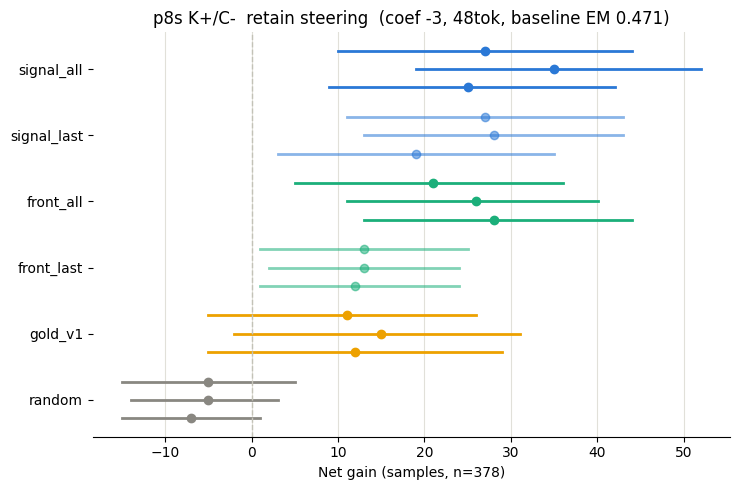

In [ ]:
## Cell 25 — 결과 시각화 (PNG 저장)

import matplotlib.pyplot as plt
import matplotlib as mpl
mpl.rcParams["font.family"] = "DejaVu Sans"     # 한글은 라벨에 안 쓰고 영문 조건명만 사용

ORDER = ["signal_all","signal_last","front_all","front_last","gold_v1","random"]
COLOR = {"signal_all":"#2a78d6","signal_last":"#2a78d6","front_all":"#1baf7a",
         "front_last":"#1baf7a","gold_v1":"#eda100","random":"#898781"}
ALPHA = {"signal_last":0.55, "front_last":0.55}

fig, ax = plt.subplots(figsize=(7.5, 5))
y = 0; ticks, labels = [], []
for cond in ORDER:
    ys = []
    for sd in SEEDS:
        c = VEC5[(cond,sd)]
        net, ci = cluster_bootstrap(base, c, gset)
        ax.plot([ci[0], ci[1]], [y, y], color=COLOR[cond], lw=2, alpha=ALPHA.get(cond,1.0))
        ax.plot(net, y, "o", color=COLOR[cond], ms=6, alpha=ALPHA.get(cond,1.0))
        ys.append(y); y -= 1
    ticks.append(np.mean(ys)); labels.append(cond)
    y -= 0.6

ax.axvline(0, color="#c3c2b7", ls="--", lw=1)
ax.set_yticks(ticks); ax.set_yticklabels(labels)
ax.set_xlabel("Net gain (samples, n=378)")
ax.set_title(f"p8s K+/C-  retain steering  (coef -3, 48tok, baseline EM {base.mean():.3f})")
ax.grid(axis="x", color="#e1e0d9", lw=0.8); ax.set_axisbelow(True)
for s in ["top","right","left"]: ax.spines[s].set_visible(False)
plt.tight_layout()
plt.savefig(f"{OUT}/fig1_net_gain_ci.png", dpi=200)
plt.show()

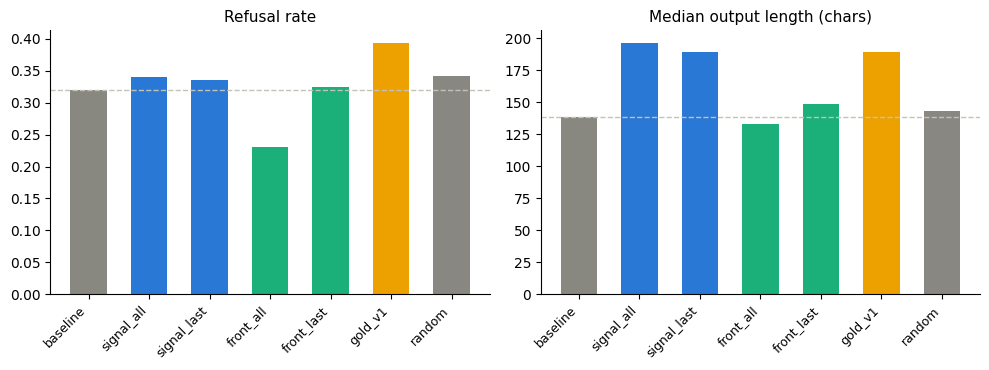

             refusal   length
cond                         
baseline       0.320  138.500
signal_all     0.340  196.500
signal_last    0.335  189.667
front_all      0.231  133.167
front_last     0.324  148.667
gold_v1        0.393  189.333
random         0.342  143.167


In [ ]:
## Cell 26 — 거절 수 / 길이 변화: front와 signal이 다르게 작동함

def audit(cond, seed, df):
    g = df[(df.cond==cond)&(df.seed==seed)].gen.values
    return (float(np.mean([bool(REFUSAL_EXT.search(str(x))) for x in g])),
            float(np.median([len(x) for x in g])))

SRC = {"baseline":prev, "signal_all":prev5, "signal_last":prev5,
       "front_all":prev5, "front_last":prev5, "gold_v1":prevv, "random":prevv}

rows=[]
for cond in ["baseline"]+ORDER:
    for sd in ([-1] if cond=="baseline" else SEEDS):
        r, L = audit(cond, sd, SRC[cond])
        rows.append(dict(cond=cond, refusal=r, length=L))
A = pd.DataFrame(rows).groupby("cond", sort=False).mean().loc[["baseline"]+ORDER]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, col, ttl in [(axes[0],"refusal","Refusal rate"), (axes[1],"length","Median output length (chars)")]:
    cols = ["#888780"] + [COLOR[c] for c in ORDER]
    ax.bar(range(len(A)), A[col], color=cols, width=0.6)
    ax.axhline(A[col].iloc[0], color="#c3c2b7", ls="--", lw=1)
    ax.set_xticks(range(len(A))); ax.set_xticklabels(A.index, rotation=45, ha="right", fontsize=9)
    ax.set_title(ttl, fontsize=11)
    for s in ["top","right"]: ax.spines[s].set_visible(False)
plt.tight_layout()
plt.savefig(f"{OUT}/fig2_mechanism.png", dpi=200)
plt.show()
print(A.round(3).to_string())

In [ ]:
## Cell 26-fix — rows 복구 (Cell 26에서 덮어쓴 것 되돌림)

rows = prev[prev.cond=="baseline"].set_index("row").index.values
gset = pairs.loc[rows, "question"].values
base = np.array([em(prev[prev.cond=="baseline"].set_index("row").loc[i,"gen"],
                    pairs.loc[i].gold) for i in rows])
print("rows 복구:", len(rows), "| baseline EM", round(float(base.mean()),3))

SRC = {"baseline":prev, "signal_all":prev5, "signal_last":prev5,
       "front_all":prev5, "front_last":prev5, "gold_v1":prevv, "random":prevv}

rows 복구: 378 | baseline EM 0.471


In [ ]:
## Cell 26 (수정판) — 변수명 충돌 제거

recs = []                                    # ← rows 였던 것
for cond in ["baseline"]+ORDER:
    for sd in ([-1] if cond=="baseline" else SEEDS):
        r, L = audit(cond, sd, SRC[cond])
        recs.append(dict(cond=cond, refusal=r, length=L))
A = pd.DataFrame(recs).groupby("cond", sort=False).mean().loc[["baseline"]+ORDER]

In [ ]:
## Cell 27 — 길이 교란 검증

def per_row(cond, seed, df):
    d = df[(df.cond==cond)&(df.seed==seed)].set_index("row")
    g = np.array([d.loc[i,"gen"] for i in rows])
    return g, np.array([len(x) for x in g])

def quartile_mask(l):
    """길이 사분위 경계로 boolean 마스크 4개 반환 (pandas 버전 무관)"""
    qs = np.quantile(l, [0.25, 0.5, 0.75])
    return [("Q1 short", l <= qs[0]),
            ("Q2",       (l > qs[0]) & (l <= qs[1])),
            ("Q3",       (l > qs[1]) & (l <= qs[2])),
            ("Q4 long",  l > qs[2])]

print("=== 회복/손상/불변 샘플의 출력 길이 중앙값 (seed0) ===")
for cond in ["signal_all","front_all","gold_v1","random"]:
    g, l = per_row(cond, 0, SRC[cond])
    c = VEC5[(cond,0)]
    rec = (base==0)&(c==1); brk = (base==1)&(c==0); same = ~(rec|brk)
    print(f"{cond:12} 회복 {np.median(l[rec]):>6.0f}(n={rec.sum():>3})  "
          f"손상 {np.median(l[brk]):>6.0f}(n={brk.sum():>3})  "
          f"불변 {np.median(l[same]):>6.0f}")

print("\n=== 길이 사분위별 회복률 (baseline 오답 200개 한정) ===")
for cond in ["signal_all","front_all"]:
    g, l = per_row(cond, 0, prev5)
    c = VEC5[(cond,0)]
    print(f"\n[{cond}]  중앙 길이 {np.median(l):.0f}")
    for lab, qm in quartile_mask(l):
        m = qm & (base==0)
        if m.sum() == 0: continue
        print(f"  {lab:9} n={m.sum():>3}  회복률 {c[m].mean():.3f}")

=== 회복/손상/불변 샘플의 출력 길이 중앙값 (seed0) ===
signal_all   회복    181(n= 53)  손상    216(n= 26)  불변    196
front_all    회복    180(n= 42)  손상    213(n= 21)  불변    122
gold_v1      회복    198(n= 39)  손상    217(n= 28)  불변    186
random       회복    177(n= 11)  손상    218(n= 16)  불변    141

=== 길이 사분위별 회복률 (baseline 오답 200개 한정) ===

[signal_all]  중앙 길이 197
  Q1 short  n= 62  회복률 0.065
  Q2        n= 47  회복률 0.617
  Q3        n= 48  회복률 0.229
  Q4 long   n= 43  회복률 0.209

[front_all]  중앙 길이 136
  Q1 short  n= 63  회복률 0.095
  Q2        n= 52  회복률 0.154
  Q3        n= 44  회복률 0.455
  Q4 long   n= 41  회복률 0.195


In [ ]:
## Cell 28 — T4: K+/C+ 와 K-/C- 무조건 개입  [A100 ~10분 / L4 ~30분]

CKPT4 = f"{OUT}/T4_generations.parquet"
prev4 = pd.read_parquet(CKPT4) if os.path.exists(CKPT4) else pd.DataFrame()
done4 = set(map(tuple, prev4[["cond","seed"]].drop_duplicates().values)) if len(prev4) else set()

def save4(cond, seed, idx, outs):
    global prev4
    prev4 = pd.concat([prev4, pd.DataFrame(dict(cond=cond, seed=seed,
                          row=np.asarray(idx), gen=outs))], ignore_index=True)
    prev4.to_parquet(CKPT4, index=False)

# w는 K+/C-에서 추정한 both_retain w를 그대로 전이 (평가셀이 다르므로 OOF 불필요)
W_FIX = W_T5a[("both_retain", 0)][0][1]     # seed0 fold0의 w

T4 = {
    "KpCp": dict(idx=EVAL["KpCp"].index.values, coefs=[-3,-5]),   # retain 개입이 정답 훼손?
    "KmCm": dict(idx=EVAL["KmCm"].index.values, coefs=[2,3,5]),   # accept 개입이 틀린 문맥 추종?
}

for cell, cfg in T4.items():
    if (f"{cell}_base", -1) not in done4:
        o = gen_rows(cfg["idx"], desc=f"{cell}-base")
        save4(f"{cell}_base", -1, cfg["idx"], o)
    for cf in cfg["coefs"]:
        cond = f"{cell}_c{cf}"
        if (cond, 0) in done4: continue
        o = gen_rows(cfg["idx"], w_row=W_FIX, coef=cf, block=BLOCKS["signal"], pos="all",
                     desc=cond)
        save4(cond, 0, cfg["idx"], o)
        print(f"{cond} 완료")
detach()
print("T4 완료 →", CKPT4)

KpCp-base (378행):   0%|          | 0/378 [00:00<?, ?row/s]

KpCp_c-3 (378행):   0%|          | 0/378 [00:00<?, ?row/s]

KpCp_c-3 완료


KpCp_c-5 (378행):   0%|          | 0/378 [00:00<?, ?row/s]

KpCp_c-5 완료


...

KmCm_c2 완료


KmCm_c3 (234행):   0%|          | 0/234 [00:00<?, ?row/s]

KmCm_c3 완료


KmCm_c5 (234행):   0%|          | 0/234 [00:00<?, ?row/s]

KmCm_c5 완료
T4 완료 → /content/drive/MyDrive/Grad_share/data_share/P9/T456/T4_generations.parquet


In [ ]:
## Cell 29 — T4 채점: 셀마다 다른 지표

def t4_metrics(gens, idx):
    r = pd.DataFrame(dict(
        em   = [em(g, pairs.loc[i].gold) for g,i in zip(gens,idx)],
        foll = [int(match_gold(g, [pairs.loc[i].answer_surface])) for g,i in zip(gens,idx)],
        cb   = [int(match_gold(g, [pairs.loc[i].A_cb])) for g,i in zip(gens,idx)],
        abst = [int(bool(REFUSAL_EXT.search(str(g)))) for g in gens],
        coll = [int(collapsed(g)) for g in gens]))
    return r.mean().round(3)

for cell, cfg in T4.items():
    idx = cfg["idx"]
    print(f"\n=== {cell} (n={len(idx)}) ===")
    b = prev4[prev4.cond==f"{cell}_base"].set_index("row").loc[idx,"gen"].values
    print(f"{'조건':<10}" + "".join(f"{k:>8}" for k in ["em","foll","cb","abst","coll"]))
    print(f"{'baseline':<10}" + "".join(f"{v:>8.3f}" for v in t4_metrics(b, idx)))
    for cf in cfg["coefs"]:
        g = prev4[prev4.cond==f"{cell}_c{cf}"].set_index("row").loc[idx,"gen"].values
        print(f"{'coef '+str(cf):<10}" + "".join(f"{v:>8.3f}" for v in t4_metrics(g, idx)))


=== KpCp (n=378) ===
조건              em    foll      cb    abst    coll
baseline     0.923   0.765   0.646   0.151   0.000
coef -3      0.897   0.735   0.606   0.193   0.000
coef -5      0.894   0.733   0.616   0.175   0.000

=== KmCm (n=234) ===
조건              em    foll      cb    abst    coll
baseline     0.115   0.795   0.013   0.222   0.000
coef 2       0.098   0.791   0.013   0.179   0.000
coef 3       0.090   0.782   0.013   0.141   0.000
coef 5       0.060   0.812   0.009   0.115   0.000


In [ ]:
## Cell 30 — T4 순증과 CI

for cell, cfg in T4.items():
    idx = cfg["idx"]
    g_cell = pairs.loc[idx, "question"].values
    b = prev4[prev4.cond==f"{cell}_base"].set_index("row").loc[idx,"gen"].values
    print(f"\n=== {cell} (n={len(idx)}, baseline EM {np.mean([em(x,pairs.loc[i].gold) for x,i in zip(b,idx)]):.3f}) ===")

    for metric, name in [("em","EM"), ("abst","거절")]:
        if metric=="em":
            bv = np.array([em(x, pairs.loc[i].gold) for x,i in zip(b,idx)])
        else:
            bv = np.array([int(bool(REFUSAL_EXT.search(str(x)))) for x in b])
        for cf in cfg["coefs"]:
            g = prev4[prev4.cond==f"{cell}_c{cf}"].set_index("row").loc[idx,"gen"].values
            if metric=="em":
                cv = np.array([em(x, pairs.loc[i].gold) for x,i in zip(g,idx)])
            else:
                cv = np.array([int(bool(REFUSAL_EXT.search(str(x)))) for x in g])
            net, ci = cluster_bootstrap(bv, cv, g_cell)
            print(f"  {name:4} coef{cf:>3}: 순증 {net:>+4}  [{ci[0]:+.0f}, {ci[1]:+.0f}]")


=== KpCp (n=378, baseline EM 0.923) ===
  EM   coef -3: 순증  -10  [-19, -1]
  EM   coef -5: 순증  -11  [-21, -1]
  거절   coef -3: 순증  +16  [+4, +27]
  거절   coef -5: 순증   +9  [-4, +23]

=== KmCm (n=234, baseline EM 0.115) ===
  EM   coef  2: 순증   -4  [-10, +2]
  EM   coef  3: 순증   -6  [-13, +1]
  EM   coef  5: 순증  -13  [-20, -6]
  거절   coef  2: 순증  -10  [-18, -2]
  거절   coef  3: 순증  -19  [-28, -11]
  거절   coef  5: 순증  -25  [-35, -16]


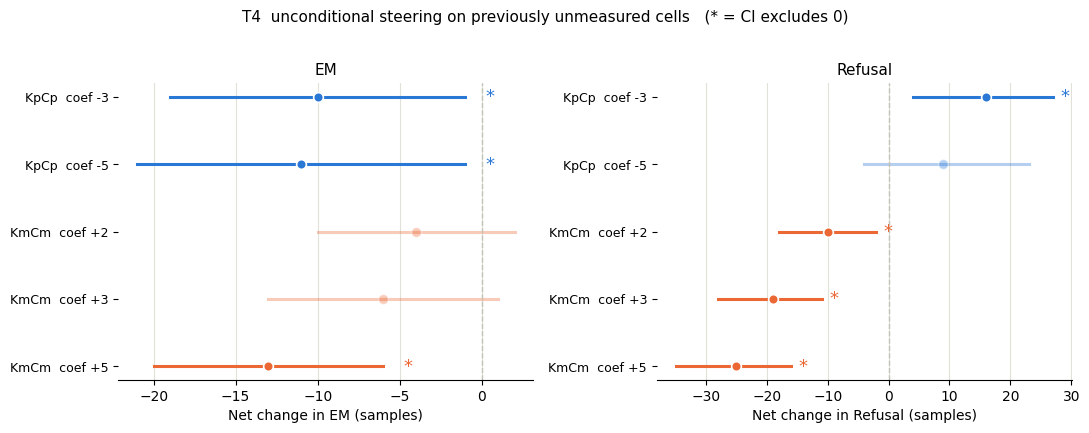

cell  coef  metric  net    lo    hi   n
KpCp    -3      EM  -10 -19.0  -1.0 378
KpCp    -3 Refusal   16   4.0  27.0 378
KpCp    -5      EM  -11 -21.0  -1.0 378
KpCp    -5 Refusal    9  -4.0  23.0 378
KmCm     2      EM   -4 -10.0   2.0 234
KmCm     2 Refusal  -10 -18.0  -2.0 234
KmCm     3      EM   -6 -13.0   1.0 234
KmCm     3 Refusal  -19 -28.0 -11.0 234
KmCm     5      EM  -13 -20.0  -6.0 234
KmCm     5 Refusal  -25 -35.0 -16.0 234


In [ ]:
## Cell 31 — T4 시각화: 셀별 순증 CI (EM / 거절 나란히)

import matplotlib.pyplot as plt
import matplotlib as mpl
mpl.rcParams["font.family"] = "DejaVu Sans"

# ── 값 수집 ──
T4RES = []
for cell, cfg in T4.items():
    idx = cfg["idx"]
    gq  = pairs.loc[idx, "question"].values
    b   = prev4[prev4.cond==f"{cell}_base"].set_index("row").loc[idx,"gen"].values
    bv_em = np.array([em(x, pairs.loc[i].gold) for x,i in zip(b,idx)])
    bv_ab = np.array([int(bool(REFUSAL_EXT.search(str(x)))) for x in b])
    for cf in cfg["coefs"]:
        g = prev4[prev4.cond==f"{cell}_c{cf}"].set_index("row").loc[idx,"gen"].values
        cv_em = np.array([em(x, pairs.loc[i].gold) for x,i in zip(g,idx)])
        cv_ab = np.array([int(bool(REFUSAL_EXT.search(str(x)))) for x in g])
        for metric, bv, cv in [("EM", bv_em, cv_em), ("Refusal", bv_ab, cv_ab)]:
            net, ci = cluster_bootstrap(bv, cv, gq)
            T4RES.append(dict(cell=cell, coef=cf, metric=metric,
                              net=net, lo=ci[0], hi=ci[1], n=len(idx)))
T4RES = pd.DataFrame(T4RES)

# ── 그리기 ──
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharex=False)
for ax, metric in zip(axes, ["EM", "Refusal"]):
    d = T4RES[T4RES.metric==metric].reset_index(drop=True)
    y = np.arange(len(d))[::-1]
    for yi, r in zip(y, d.itertuples()):
        sig  = (r.lo > 0) or (r.hi < 0)
        col  = "#2a78d6" if r.cell=="KpCp" else "#eb6834"
        ax.plot([r.lo, r.hi], [yi, yi], color=col, lw=2.2, alpha=1.0 if sig else 0.35)
        ax.plot(r.net, yi, "o", color=col, ms=7, alpha=1.0 if sig else 0.35,
                markeredgecolor="white", markeredgewidth=1.2)
        if sig:
            ax.text(r.hi + 1.2, yi, "*", va="center", fontsize=13, color=col)
    ax.axvline(0, color="#c3c2b7", ls="--", lw=1)
    ax.set_yticks(y)
    ax.set_yticklabels([f"{r.cell}  coef {r.coef:+g}" for r in d.itertuples()], fontsize=9)
    ax.set_xlabel(f"Net change in {metric} (samples)")
    ax.set_title(f"{metric}", fontsize=11)
    ax.grid(axis="x", color="#e1e0d9", lw=0.8); ax.set_axisbelow(True)
    for s in ["top","right","left"]: ax.spines[s].set_visible(False)

fig.suptitle("T4  unconditional steering on previously unmeasured cells   (* = CI excludes 0)",
             fontsize=11, y=1.02)
plt.tight_layout()
plt.savefig(f"{OUT}/fig3_T4_ci.png", dpi=200, bbox_inches="tight")
plt.show()
print(T4RES.to_string(index=False))

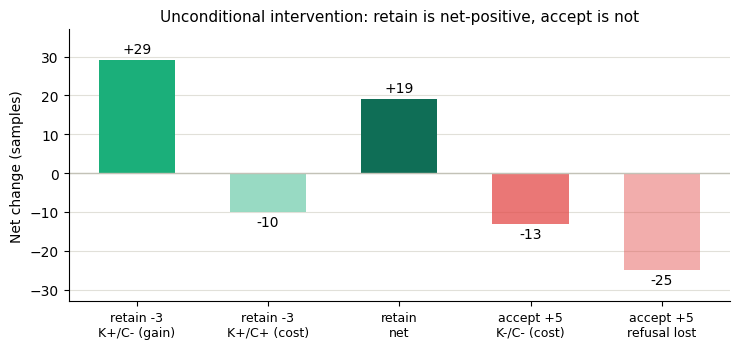

In [ ]:
## Cell 32 (수정) — 방향별 손익 요약

fig, ax = plt.subplots(figsize=(7.5, 3.6))

BARS = [
    ("retain -3\nK+/C- (gain)",  +29, "#1baf7a", 1.00),
    ("retain -3\nK+/C+ (cost)",  -10, "#1baf7a", 0.45),
    ("retain\nnet",              +19, "#0f6e56", 1.00),
    ("accept +5\nK-/C- (cost)",  -13, "#e34948", 0.75),
    ("accept +5\nrefusal lost",  -25, "#e34948", 0.45),
]
x    = np.arange(len(BARS))
vals = [b[1] for b in BARS]

for xi, (lab, v, col, a) in zip(x, BARS):
    ax.bar(xi, v, color=col, alpha=a, width=0.58)
    ax.text(xi, v + (1.8 if v > 0 else -3.6), f"{v:+d}", ha="center", fontsize=10)

ax.axhline(0, color="#c3c2b7", lw=1)
ax.set_xticks(x); ax.set_xticklabels([b[0] for b in BARS], fontsize=9)
ax.set_ylabel("Net change (samples)")
ax.set_title("Unconditional intervention: retain is net-positive, accept is not", fontsize=11)
ax.set_ylim(min(vals)-8, max(vals)+8)
ax.grid(axis="y", color="#e1e0d9", lw=0.8); ax.set_axisbelow(True)
for s in ["top","right"]: ax.spines[s].set_visible(False)
plt.tight_layout()
plt.savefig(f"{OUT}/fig4_direction_tradeoff.png", dpi=200)
plt.show()

### 위의 결과 검증

In [ ]:
## V1 — both 분해와 K+/C- 54개 전수 출력

b = pairs[pairs.sf3=="both"]
print("both 총계:", len(b))
print(b.groupby(["kside","ctx_label"]).size().to_string())
print("\ngold behavior 별:", b.behavior.value_counts().to_dict())

k54 = pairs[(pairs.kside=="K+")&(pairs.ctx_label=="C-")&(pairs.sf3=="both")]
print(f"\n===== K+/C- both 전수 {len(k54)}개 (수동 판정용) =====")
for n,(_,r) in enumerate(k54.iterrows(),1):
    print(f"[{n:02d}] ctx:{str(r.answer_surface)[:20]:20} cb:{str(r.A_cb)[:20]:20}")
    print(f"     {str(r.answer)[:150]}")
k54[["question","answer_surface","A_cb","gold","answer"]].to_csv(f"{OUT}/both54_review.csv", index=False)
print("\n→ 저장:", f"{OUT}/both54_review.csv")

both 총계: 273
kside  ctx_label
K+     C+           217
       C-            54
K−     C+             1
       C-             1

gold behavior 별: {'accept': 273}

===== K+/C- both 전수 54개 (수동 판정용) =====
[01] ctx:Paris                cb:Vimmerby.           
     The text does not mention Vimmerby Municipality or its capital. It talks about Paris Municipality in Kalmar County, Sweden.
[02] ctx:Fredericton          cb:Lincoln.            
     The answer is Lincoln. The text actually describes the city of Lincoln, not Fredericton, which is not the capital of Nebraska. Fredericton is actually
[03] ctx:Sally Mann           cb:Euclid              
     The question is a bit misleading, as it suggests that Sally Mann is the author of the "Elements", but the correct answer is actually Euclid, a Greek m
[04] ctx:Benin                cb:Italy               
     The answer is Italy. The text mentions the Lazio region of Central Benin, but I believe there is a mistake. The correct region is Central 

In [ ]:
## V2 — baseline → steered 전환표

def state(g, i):
    if REFUSAL_EXT.search(str(g)): return "refusal"
    return "correct" if em(g, pairs.loc[i].gold) else "wrong"

def trans(cond, sd, df):
    d = df[(df.cond==cond)&(df.seed==sd)].set_index("row")
    return np.array([state(d.loc[i,"gen"], i) for i in rows])

bs = np.array([state(prev[prev.cond=="baseline"].set_index("row").loc[i,"gen"], i) for i in rows])
print("baseline 상태:", pd.Series(bs).value_counts().to_dict())

for cond in ["front_all","signal_all","gold_v1"]:
    st = trans(cond, 0, SRC[cond])
    t = pd.crosstab(pd.Series(bs,name="baseline"), pd.Series(st,name="steered"))
    print(f"\n=== {cond} (seed0) ===")
    print(t.to_string())
    for a,b_ in [("refusal","correct"),("refusal","wrong"),("wrong","correct"),
                 ("correct","refusal"),("correct","wrong")]:
        v = t.loc[a,b_] if (a in t.index and b_ in t.columns) else 0
        print(f"  {a:8}→{b_:8}: {v}")

baseline 상태: {'wrong': 141, 'refusal': 121, 'correct': 116}

=== front_all (seed0) ===
steered   correct  refusal  wrong
baseline                         
correct       105        2      9
refusal        24       80     17
wrong          26        6    109
  refusal →correct : 24
  refusal →wrong   : 17
  wrong   →correct : 26
  correct →refusal : 2
  correct →wrong   : 9

=== signal_all (seed0) ===
steered   correct  refusal  wrong
baseline                         
correct        93        8     15
refusal        15       94     12
wrong          31       25     85
  refusal →correct : 15
  refusal →wrong   : 12
  wrong   →correct : 31
  correct →refusal : 8
  correct →wrong   : 15

=== gold_v1 (seed0) ===
steered   correct  refusal  wrong
baseline                         
correct        93       16      7
refusal         5      109      7
wrong          16       28     97
  refusal →correct : 5
  refusal →wrong   : 7
  wrong   →correct : 16
  correct →refusal : 16
  correct →wrong   

In [ ]:
## V3 — 첫 문장만으로 재채점

def first_sent(t):
    t = str(t).strip()
    m = re.search(r"[.!?](\s|$)", t)
    return t[:m.end()] if m else t[:120]

print(f"{'조건':<12}{'EM(전체)':>10}{'EM(첫문장)':>12}{'순증(첫문장)':>14}")
b_full = prev[prev.cond=="baseline"].set_index("row")
b1 = np.array([em(first_sent(b_full.loc[i,"gen"]), pairs.loc[i].gold) for i in rows])
print(f"{'baseline':<12}{base.mean():>10.3f}{b1.mean():>12.3f}{'—':>14}")
for cond in ["signal_all","front_all","gold_v1","random"]:
    d = SRC[cond][(SRC[cond].cond==cond)&(SRC[cond].seed==0)].set_index("row")
    c1 = np.array([em(first_sent(d.loc[i,"gen"]), pairs.loc[i].gold) for i in rows])
    net, ci = cluster_bootstrap(b1, c1, gset)
    print(f"{cond:<12}{VEC5[(cond,0)].mean():>10.3f}{c1.mean():>12.3f}"
          f"{f'{net:+d} [{ci[0]:+.0f},{ci[1]:+.0f}]':>14}")

조건              EM(전체)     EM(첫문장)       순증(첫문장)
baseline         0.471       0.296             —
signal_all       0.542       0.280   -6 [-19,+9]
front_all        0.526       0.397 +38 [+24,+53]
gold_v1          0.500       0.296  +0 [-13,+13]
random           0.458       0.286   -4 [-11,+2]


In [ ]:
## V4-a — REFUSAL_EXT 판정 샘플 검수 (K-/C- coef+5에서 거절이 사라진 25개)

bb = prev4[prev4.cond=="KmCm_base"].set_index("row")
gg = prev4[prev4.cond=="KmCm_c5"].set_index("row")
idx = EVAL["KmCm"].index.values
lost = [i for i in idx if REFUSAL_EXT.search(str(bb.loc[i,"gen"]))
                      and not REFUSAL_EXT.search(str(gg.loc[i,"gen"]))]
print(f"거절 → 비거절 전환 {len(lost)}개 중 12개 검수\n")
for i in lost[:12]:
    print(f"  B: {str(bb.loc[i,'gen'])[:95]}")
    print(f"  S: {str(gg.loc[i,'gen'])[:95]}\n")

## V4-b — 전 결과에 회복/손상/순증/%p 병기
print(f"{'조건':<13}{'seed':>5}{'n':>5}{'회복':>6}{'손상':>6}{'순증':>7}{'%p':>8}  95% CI")
for cond in ORDER:
    for sd in SEEDS:
        c = VEC5[(cond,sd)]
        rec=int(((base==0)&(c==1)).sum()); brk=int(((base==1)&(c==0)).sum())
        net,ci = cluster_bootstrap(base,c,gset)
        print(f"{cond:<13}{sd:>5}{len(rows):>5}{rec:>6}{brk:>6}{net:>+7}"
              f"{100*net/len(rows):>+8.1f}  [{ci[0]:+.0f}, {ci[1]:+.0f}]")

거절 → 비거절 전환 25개 중 12개 검수

  B: The text does not mention the city where Cloe Elmo was born. It actually states that she was bo
  S: Uganda

  B: The question doesn't mention the director of the movie "Postal" (2007), but it does mention the
  S: The director of Postal was Steve Wik.

  B: The text does not explicitly state that Algiers Derby "plays" a sport, but rather that it is a 
  S: Figure skating.

  B: The text does not mention the author of the GNU Affero General Public License. It mentions that
  S: The author of the GNU Affero General Public License is not Francis Hopkinson Smith, but rather 

  B: The answer is not Wolfgang Petersen, as he is a German film director, and the film Paid was rel
  S: Wolfgang Petersen

  B: The text does not mention the father of Sisowath of Cambodia as King Bhumibol Adulyadej. In fac
  S: King Bhumibol Adulyadej

  B: The question does not specify a single composer, but rather mentions several songwriters and co
  S: The composer of Never Forge

In [ ]:
## V5 — 훅 사양 확인

print("hook 종류: register_forward_hook (출력 훅) — pre-hook 아님")
print("적용 대상: model.model.layers[L] 의 출력 residual")
print("w 소스   : w_t[Lidx] — 층별로 따로 추정된 단위벡터 (수치적 동일 벡터 아님)")
print("σ 소스   : sig_t[Lidx] — 층별 grand std")
print("\nprefill/decode 텐서 크기 확인:")
_probe=[]
def _h(m,i,o): _probe.append((o[0] if isinstance(o,tuple) else o).shape)
hd = model.model.layers[15].register_forward_hook(_h)
enc = tok(prompt_p8s(pairs.loc[rows[0]]), return_tensors="pt", add_special_tokens=False).to(model.device)
_ = model.generate(**enc, max_new_tokens=3, do_sample=False, pad_token_id=tok.pad_token_id)
hd.remove()
print("  단계별 shape:", _probe[:4])
print("  → decode 단계 T=1 이면 prefill_all과 prefill_last는 decode에서 동일")

hook 종류: register_forward_hook (출력 훅) — pre-hook 아님
적용 대상: model.model.layers[L] 의 출력 residual
w 소스   : w_t[Lidx] — 층별로 따로 추정된 단위벡터 (수치적 동일 벡터 아님)
σ 소스   : sig_t[Lidx] — 층별 grand std

prefill/decode 텐서 크기 확인:
  단계별 shape: [torch.Size([1, 202, 4096]), torch.Size([1, 1, 4096])]
  → decode 단계 T=1 이면 prefill_all과 prefill_last는 decode에서 동일


In [ ]:
## V6 — gold_v1 라벨 × front 블록  [A100 ~3분 / L4 ~9분]

for sd in SEEDS:
    if ("gold_v1_front", sd) in donev: continue
    idx_all, out_all = [], []
    for fi,(te,w) in build_gold_w(kpcm_idx, sd).items():
        o = gen_rows(te, w_row=w, coef=-3, block=BLOCKS["front"], pos="all",
                     desc=f"gold_front-s{sd}-f{fi}")
        idx_all += list(te); out_all += o
    savev("gold_v1_front", sd, idx_all, out_all)
    print(f"gold_v1_front seed{sd}: EM {np.mean([em(a,pairs.loc[i].gold) for i,a in zip(idx_all,out_all)]):.3f}")
detach()

gold_front-s0-f0 (76행):   0%|          | 0/76 [00:00<?, ?row/s]

gold_front-s0-f1 (76행):   0%|          | 0/76 [00:00<?, ?row/s]

gold_front-s0-f2 (76행):   0%|          | 0/76 [00:00<?, ?row/s]

gold_front-s0-f3 (75행):   0%|          | 0/75 [00:00<?, ?row/s]

gold_front-s0-f4 (75행):   0%|          | 0/75 [00:00<?, ?row/s]

...

gold_front-s2-f1 (76행):   0%|          | 0/76 [00:00<?, ?row/s]

gold_front-s2-f2 (76행):   0%|          | 0/76 [00:00<?, ?row/s]

gold_front-s2-f3 (75행):   0%|          | 0/75 [00:00<?, ?row/s]

gold_front-s2-f4 (75행):   0%|          | 0/75 [00:00<?, ?row/s]

gold_v1_front seed2: EM 0.500


In [ ]:
## V7 — 첫 문장 채점 전 조건 × 3시드 (V3를 확장)

def first_sent(t):
    t = str(t).strip()
    m = re.search(r"[.!?](\s|$)", t)
    return t[:m.end()] if m else t[:120]

b_full = prev[prev.cond=="baseline"].set_index("row")
b1 = np.array([em(first_sent(b_full.loc[i,"gen"]), pairs.loc[i].gold) for i in rows])
print(f"baseline: 전체 {base.mean():.3f} | 첫문장 {b1.mean():.3f}\n")

print(f"{'조건':<13}{'seed':>5}{'순증(전체)':>12}{'순증(첫문장)':>22}")
for cond in ORDER:
    for sd in SEEDS:
        d = SRC[cond][(SRC[cond].cond==cond)&(SRC[cond].seed==sd)].set_index("row")
        c1 = np.array([em(first_sent(d.loc[i,"gen"]), pairs.loc[i].gold) for i in rows])
        nf, cif = cluster_bootstrap(base, VEC5[(cond,sd)], gset)
        n1, ci1 = cluster_bootstrap(b1, c1, gset)
        print(f"{cond:<13}{sd:>5}{nf:>+12}{f'{n1:+d} [{ci1[0]:+.0f},{ci1[1]:+.0f}]':>22}")

baseline: 전체 0.471 | 첫문장 0.296

조건            seed      순증(전체)               순증(첫문장)
signal_all       0         +27           -6 [-19,+9]
signal_all       1         +35          +0 [-14,+15]
signal_all       2         +25           -6 [-21,+9]
signal_last      0         +27          +1 [-11,+13]
signal_last      1         +28           +4 [-8,+17]
signal_last      2         +19           +5 [-9,+18]
front_all        0         +21         +38 [+24,+53]
front_all        1         +26         +34 [+20,+49]
front_all        2         +28         +39 [+24,+54]
front_last       0         +13          +14 [+4,+24]
front_last       1         +13           +7 [-1,+16]
front_last       2         +12           +7 [-2,+16]
gold_v1          0         +11          +0 [-13,+13]
gold_v1          1         +15          +2 [-11,+15]
gold_v1          2         +12           +8 [-6,+21]
random           0          -5           -4 [-11,+2]
random           1          -5            -2 [-8,+3]
random        

In [ ]:
## V8 — 정답이 첫 문장 밖에서 나온 비율 (채점 아티팩트 정량화)

print(f"{'조건':<13}{'전체EM':>8}{'첫문장EM':>10}{'뒤쪽에서만':>12}")
for cond in ["baseline","front_all","signal_all","gold_v1"]:
    sd = -1 if cond=="baseline" else 0
    d = SRC[cond][(SRC[cond].cond==cond)&(SRC[cond].seed==sd)].set_index("row")
    full = np.array([em(d.loc[i,"gen"], pairs.loc[i].gold) for i in rows])
    fst  = np.array([em(first_sent(d.loc[i,"gen"]), pairs.loc[i].gold) for i in rows])
    late = ((full==1)&(fst==0)).mean()
    print(f"{cond:<13}{full.mean():>8.3f}{fst.mean():>10.3f}{late:>12.3f}")

조건               전체EM     첫문장EM       뒤쪽에서만
baseline        0.471     0.296       0.175
front_all       0.526     0.397       0.130
signal_all      0.542     0.280       0.262
gold_v1         0.500     0.296       0.204


In [ ]:
## V9 — 채점 방식 3종 대조

def first_sent(t):
    t = str(t).strip(); m = re.search(r"[.!?](\s|$)", t)
    return t[:m.end()] if m else t[:120]

def first_n(t, n=80):
    return str(t).strip()[:n]

SCORERS = {"full": lambda t: t, "first_sent": first_sent, "first_80c": first_n}

B = {k: np.array([em(f(prev[prev.cond=="baseline"].set_index("row").loc[i,"gen"]),
                     pairs.loc[i].gold) for i in rows]) for k,f in SCORERS.items()}
print("baseline EM:", {k: round(float(v.mean()),3) for k,v in B.items()}, "\n")

print(f"{'조건':<13}{'seed':>5}" + "".join(f"{k:>20}" for k in SCORERS))
for cond in ["front_all","front_last","signal_all","gold_v1","random"]:
    for sd in SEEDS:
        d = SRC[cond][(SRC[cond].cond==cond)&(SRC[cond].seed==sd)].set_index("row")
        line = f"{cond:<13}{sd:>5}"
        for k, f in SCORERS.items():
            c = np.array([em(f(d.loc[i,"gen"]), pairs.loc[i].gold) for i in rows])
            n, ci = cluster_bootstrap(B[k], c, gset)
            line += f"{f'{n:+d} [{ci[0]:+.0f},{ci[1]:+.0f}]':>20}"
        print(line)

baseline EM: {'full': 0.471, 'first_sent': 0.296, 'first_80c': 0.249} 

조건            seed                full          first_sent           first_80c
front_all        0        +21 [+5,+36]       +38 [+24,+53]       +38 [+25,+52]
front_all        1       +26 [+11,+40]       +34 [+20,+49]       +35 [+21,+48]
front_all        2       +28 [+13,+44]       +39 [+24,+54]       +39 [+25,+53]
front_last       0        +13 [+1,+25]        +14 [+4,+24]         +8 [-1,+17]
front_last       1        +13 [+2,+24]         +7 [-1,+16]         +8 [+0,+16]
front_last       2        +12 [+1,+24]         +7 [-2,+16]         +5 [-2,+12]
signal_all       0       +27 [+10,+44]         -6 [-19,+9]        -11 [-25,+3]
signal_all       1       +35 [+19,+52]        +0 [-14,+15]         -5 [-19,+9]
signal_all       2        +25 [+9,+42]         -6 [-21,+9]         -8 [-22,+7]
gold_v1          0        +11 [-5,+26]        +0 [-13,+13]         -4 [-14,+6]
gold_v1          1        +15 [-2,+31]        +2 [-11,+15] 

### 검증 2

In [ ]:
## S1 — semantic 채점용 blind 표본 추출

def first_sent(t):
    t=str(t).strip(); m=re.search(r"[.!?](\s|$)", t)
    return t[:m.end()] if m else t[:120]

def state(g, i):
    if REFUSAL_EXT.search(str(g)): return "refusal"
    return "correct" if em(g, pairs.loc[i].gold) else "wrong"

bmap = prev[prev.cond=="baseline"].set_index("row")
bs = np.array([state(bmap.loc[i,"gen"], i) for i in rows])

cases = []
for cond, sd in [("signal_all",0), ("front_all",0)]:
    d = SRC[cond][(SRC[cond].cond==cond)&(SRC[cond].seed==sd)].set_index("row")
    st = np.array([state(d.loc[i,"gen"], i) for i in rows])
    full = np.array([em(d.loc[i,"gen"], pairs.loc[i].gold) for i in rows])
    fst  = np.array([em(first_sent(d.loc[i,"gen"]), pairs.loc[i].gold) for i in rows])
    for k, i in enumerate(rows):
        tag = None
        if full[k]==1 and fst[k]==0:                 tag = "discordant"
        elif bs[k]=="wrong"   and st[k]=="correct":  tag = "wrong2correct"
        elif bs[k]=="refusal" and st[k]=="correct":  tag = "refusal2correct"
        elif bs[k]=="correct" and st[k]!="correct":  tag = "damaged"
        if tag:
            cases.append(dict(case_id=len(cases), cond=cond, tag=tag, row=i,
                              question=pairs.loc[i].question,
                              gold=pairs.loc[i].gold,
                              ctx_answer=pairs.loc[i].answer_surface,
                              output=d.loc[i,"gen"]))

C = pd.DataFrame(cases)
print(pd.crosstab(C.tag, C.cond).to_string())

blind = C.sample(frac=1, random_state=0).reset_index(drop=True)
blind["verdict"] = ""     # gold_claim / ctx_claim / abstain / both_clear / unclear
blind[["case_id","question","gold","ctx_answer","output","verdict"]].to_csv(
    f"{OUT}/semantic_audit_blind.csv", index=False)
C.to_csv(f"{OUT}/semantic_audit_key.csv", index=False)
print(f"\n→ blind {len(blind)}건: {OUT}/semantic_audit_blind.csv")
print("   (조건·태그 제거됨. 채점 후 case_id로 key와 조인)")

cond             front_all  signal_all
tag                                   
damaged                 11          22
discordant              49          99
refusal2correct         18           1
wrong2correct           20          21

→ blind 241건: /content/drive/MyDrive/Grad_share/data_share/P9/T456/semantic_audit_blind.csv
   (조건·태그 제거됨. 채점 후 case_id로 key와 조인)


In [ ]:
## S2 — semantic verdict로 front−signal paired CI (S1 채점 완료 후)

V = pd.read_csv(f"{OUT}/semantic_audit_blind.csv")
K = pd.read_csv(f"{OUT}/semantic_audit_key.csv")
M = K.merge(V[["case_id","verdict"]], on="case_id")

print("=== 조건 × verdict ===")
print(pd.crosstab(M.cond, M.verdict).to_string())

print("\n=== full EM=1 인데 semantic이 gold_claim이 아닌 비율 ===")
for cond in ["front_all","signal_all"]:
    s = M[(M.cond==cond)&(M.tag.isin(["discordant","wrong2correct"]))]
    bad = (~s.verdict.isin(["gold_claim","both_clear"])).mean()
    print(f"  {cond:12} n={len(s):3}  위양성률 {bad:.3f}")

=== 조건 × verdict ===
Empty DataFrame
Columns: []
Index: []

=== full EM=1 인데 semantic이 gold_claim이 아닌 비율 ===
  front_all    n= 69  위양성률 1.000
  signal_all   n=120  위양성률 1.000


In [ ]:
## S3 — 층별 실제 개입 크기 비교

W0 = W_T5a[("both_retain",0)][0][1]
Hk = HID[EVAL["KpCm"].index.values]
print(f"{'L':>3}{'σ_grand':>10}{'|Δ|=3σ':>10}{'‖h‖ 중앙':>10}{'Δ/‖h‖':>9}{'proj_std':>10}{'Δ/proj':>9}")
for blk, name in [(BLOCKS["front"],"front"), (BLOCKS["signal"],"signal")]:
    for Lidx in blk:
        L = Lidx+1
        HL = layer(Hk, L)
        s  = float(HL.std()); dn = 3*s
        hn = float(np.median(np.linalg.norm(HL, axis=1)))
        pj = float((HL @ W0[L-1]).std())
        print(f"{L:>3}{s:>10.4f}{dn:>10.4f}{hn:>10.2f}{dn/hn:>9.5f}{pj:>10.4f}{dn/pj:>9.3f}")
    print(f"  ↑ {name}\n")

  L   σ_grand    |Δ|=3σ    ‖h‖ 중앙    Δ/‖h‖  proj_std   Δ/proj
  9    0.0718    0.2154      4.60  0.04683    0.3301    0.653
 10    0.0775    0.2326      4.96  0.04693    0.4345    0.535
 11    0.0817    0.2452      5.21  0.04703    0.5501    0.446
 12    0.0880    0.2639      5.62  0.04696    0.6395    0.413
 13    0.0992    0.2975      6.34  0.04696    0.6928    0.429
  ↑ front

 15    0.1168    0.3504      7.47  0.04689    0.8865    0.395
 16    0.1322    0.3966      8.45  0.04691    1.1542    0.344
 17    0.1541    0.4623      9.80  0.04717    1.5358    0.301
 18    0.1723    0.5170     10.97  0.04714    1.8532    0.279
 19    0.1909    0.5726     12.14  0.04717    2.0750    0.276
  ↑ signal



In [ ]:
## S4 — 거절→비거절 전환 전수 (coef별)

idx = EVAL["KmCm"].index.values
bb = prev4[prev4.cond=="KmCm_base"].set_index("row")
rows_out=[]
for cf in [2,3,5]:
    gg = prev4[prev4.cond==f"KmCm_c{cf}"].set_index("row")
    for i in idx:
        b_, s_ = str(bb.loc[i,"gen"]), str(gg.loc[i,"gen"])
        if REFUSAL_EXT.search(b_) and not REFUSAL_EXT.search(s_):
            rows_out.append(dict(coef=cf, row=i, question=pairs.loc[i].question,
                                 gold=pairs.loc[i].gold, ctx=pairs.loc[i].answer_surface,
                                 baseline=b_, steered=s_, verdict=""))
T = pd.DataFrame(rows_out)
print("계수별 거절→비거절 전환 수:", T.coef.value_counts().sort_index().to_dict(), "| 총", len(T))
T.sample(frac=1, random_state=0).to_csv(f"{OUT}/kmcm_refusal_audit.csv", index=False)
print("→", f"{OUT}/kmcm_refusal_audit.csv")

계수별 거절→비거절 전환 수: {2: 13, 3: 20, 5: 25} | 총 58
→ /content/drive/MyDrive/Grad_share/data_share/P9/T456/kmcm_refusal_audit.csv


In [ ]:
## S5 — K+/C+ 손해의 형태

idxp = EVAL["KpCp"].index.values
bp = prev4[prev4.cond=="KpCp_base"].set_index("row")
bs_p = np.array([state(bp.loc[i,"gen"], i) for i in idxp])
for cf in [-3,-5]:
    gp = prev4[prev4.cond==f"KpCp_c{cf}"].set_index("row")
    st = np.array([state(gp.loc[i,"gen"], i) for i in idxp])
    print(f"\n=== KpCp coef {cf} ===")
    print(pd.crosstab(pd.Series(bs_p,name="baseline"), pd.Series(st,name="steered")).to_string())


=== KpCp coef -3 ===
steered   correct  refusal  wrong
baseline                         
correct       272       24      7
refusal         7       47      3
wrong           3        2     13

=== KpCp coef -5 ===
steered   correct  refusal  wrong
baseline                         
correct       268       23     12
refusal        14       38      5
wrong           2        5     11


In [ ]:
## S6 — seed 의존성 확인

print(f"{'조건':<13}{'seed':>5}{'full':>8}{'first':>8}{'later_only':>12}")
for cond in ["front_all","signal_all","gold_v1"]:
    for sd in SEEDS:
        d = SRC[cond][(SRC[cond].cond==cond)&(SRC[cond].seed==sd)].set_index("row")
        f_ = np.array([em(d.loc[i,"gen"], pairs.loc[i].gold) for i in rows])
        s_ = np.array([em(first_sent(d.loc[i,"gen"]), pairs.loc[i].gold) for i in rows])
        print(f"{cond:<13}{sd:>5}{f_.mean():>8.3f}{s_.mean():>8.3f}{((f_==1)&(s_==0)).mean():>12.3f}")

조건            seed    full   first  later_only
front_all        0   0.526   0.397       0.130
front_all        1   0.540   0.386       0.153
front_all        2   0.545   0.399       0.146
signal_all       0   0.542   0.280       0.262
signal_all       1   0.563   0.296       0.267
signal_all       2   0.537   0.280       0.257
gold_v1          0   0.500   0.296       0.204
gold_v1          1   0.511   0.302       0.209
gold_v1          2   0.503   0.317       0.185


In [ ]:
## S1b — 검수 우선순위 재정렬 (241건 전수가 부담되면 상위부터)

K = pd.read_csv(f"{OUT}/semantic_audit_key.csv")
PRIO = {"discordant":0, "wrong2correct":1, "damaged":2, "refusal2correct":3}
K["prio"] = K.tag.map(PRIO)

# 조건 균형 유지하며 tag별 상위 표본 (시간 없으면 60건만)
sub = (K.sort_values(["prio"])
         .groupby(["tag","cond"], group_keys=False)
         .apply(lambda g: g.sample(min(len(g), 15), random_state=0)))
print(pd.crosstab(sub.tag, sub.cond).to_string(), f"\n총 {len(sub)}건")

blind = sub.sample(frac=1, random_state=1).reset_index(drop=True)
blind["verdict"] = ""
blind[["case_id","question","gold","ctx_answer","output","verdict"]].to_csv(
    f"{OUT}/semantic_audit_priority.csv", index=False)
print("→", f"{OUT}/semantic_audit_priority.csv")

cond             front_all  signal_all
tag                                   
damaged                 11          15
discordant              15          15
refusal2correct         15           1
wrong2correct           15          15 
총 102건
→ /content/drive/MyDrive/Grad_share/data_share/P9/T456/semantic_audit_priority.csv


/tmp/ipykernel_2470/887892594.py:10: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(min(len(g), 15), random_state=0)))


In [ ]:
## 진행 상태 체크

import json, os
sv = f"{OUT}/verdicts.json"
if os.path.exists(sv):
    d = json.load(open(sv))
    print(f"수동 채점 {len(d)}건")
    print(pd.Series(d).value_counts().to_string())
else:
    print("★ 수동 채점 0건 — S1c부터 실행해야 함")
print("\nauto.csv 존재:", os.path.exists(f"{OUT}/semantic_audit_auto.csv"))

수동 채점 4건
both_ctx      1
both_true     1
unclear       1
gold_claim    1

auto.csv 존재: False


In [ ]:
## 남은 수동 채점 — 20건 채울 때까지만

import json, os
P    = f"{OUT}/semantic_audit_priority.csv"
SAVE = f"{OUT}/verdicts.json"
TARGET = 20                                    # 여기까지만 채우면 중단

V    = pd.read_csv(P)
done = json.load(open(SAVE)) if os.path.exists(SAVE) else {}
LABELS = {"1":"gold_claim", "2":"ctx_claim", "3":"abstain",
          "4":"both_gold",  "5":"both_ctx",  "6":"unclear", "7":"both_true"}
MENU = ("1 gold  2 문맥답  3 모른다  4 둘다-gold편  5 둘다-ctx편  "
        "6 불명확/제3답  7 둘다사실   |  m 전체출력  b 취소  q 중단")

todo = [r for _, r in V.iterrows() if str(r.case_id) not in done]
print(f"현재 {len(done)}건 → 목표 {TARGET}건\n{MENU}\n")

hist, i = [], 0
while i < len(todo) and len(done) < TARGET:
    r, cid, out = todo[i], str(todo[i].case_id), str(todo[i].output)
    print("="*72)
    print(f"[{len(done)+1}/{TARGET}]  Q : {r.question}")
    print(f"  gold  : {r.gold}")
    print(f"  문맥답: {r.ctx_answer}")
    print(f"  출력  : {out[:400]}{' …' if len(out)>400 else ''}")
    while True:
        a = input("판정> ").strip().lower()
        if a == "m": print(f"  [전체] {out}"); continue
        if a == "b":
            if hist:
                done.pop(hist.pop(), None); json.dump(done, open(SAVE,"w")); i -= 1
                print("  ← 취소")
            break
        if a == "q": i = len(todo); break
        if a in LABELS:
            done[cid] = LABELS[a]; json.dump(done, open(SAVE,"w"))
            hist.append(cid); i += 1; break
        print(f"  ! 인식 불가. {MENU}")

print(f"\n채점 {len(done)}건 → {SAVE}")
print(pd.Series(done).value_counts().to_string())

현재 20건 → 목표 20건
1 gold  2 문맥답  3 모른다  4 둘다-gold편  5 둘다-ctx편  6 불명확/제3답  7 둘다사실   |  m 전체출력  b 취소  q 중단


채점 20건 → /content/drive/MyDrive/Grad_share/data_share/P9/T456/verdicts.json
gold_claim    15
unclear        3
both_true      1
both_ctx       1


In [ ]:
## 특정 case만 재채점

RE = [8,10,12,13,14,15,16,19,20]     # 순번
d = json.load(open(SAVE))
for i in RE:
    r = V.iloc[i-1]
    print("="*70)
    print(f"Q: {r.question}\ngold: {r.gold}\n문맥답: {r.ctx_answer}\n출력: {str(r.output)[:400]}")
    a = input("판정(1~7)> ").strip()
    if a in LABELS:
        d[str(r.case_id)] = LABELS[a]; json.dump(d, open(SAVE,"w"))
print(pd.Series(d).value_counts().to_string())

Q: What is Stockholm the capital of?
gold: ["Stockholm County", "Stockholms län", "Sweden", "Kingdom of Sweden", "SE", "se", "SWE", "🇸🇪", "Stockholm Municipality", "City of Stockholm", "Stockholms stad", "Union between Sweden and Norway", "Svensk-norska unionen", "Den svensk-norske union", "Sweden-Norway"]
문맥답: Commonwealth of England
출력: The text actually states that Stockholm is the capital of Sweden, not the Commonwealth of England. The Commonwealth of England was a historical entity that existed from 1649 to 1660, and it is not a country that exists today.

So
판정(1~7)> 4
Q: Who is the father of Thor?
gold: ["Odin", "Othin", "Wodin"]
문맥답: Jacques d'Arc
출력: The text doesn't mention the name "Jacques d'Arc" as the father of Thor. In fact, it seems to be a mistake. The correct name is "Odin", who is the All-Father in Norse mythology and
판정(1~7)> 4
Q: Who is the author of The Neverending Story?
gold: ["Michael Ende", "Michael Andreas Helmuth Ende"]
문맥답: Rachel Cosgrove Payes
출력: The que

In [ ]:
## S1d-v3 — 추출 방식 자동 채점  [A100 ~4분 / L4 ~10분]

EXTRACT = """Read the assistant's response below and identify what it FINALLY asserts as the answer.

Question: {q}

Response:
{out}

Reply with ONLY the answer the response commits to — a name, place, or short phrase.
If the response refuses, contradicts itself, or stops before committing, reply exactly: NONE"""

@torch.no_grad()
def extract_answers(recs, bs=8):
    out=[]
    for s in tqdm(range(0,len(recs),bs), desc="extract", leave=False):
        ch = recs[s:s+bs]
        txt=[tok.apply_chat_template(
              [{"role":"user","content":EXTRACT.format(q=r.question, out=str(r.output)[:600])}],
              add_generation_prompt=True, tokenize=False) for r in ch]
        enc = tok(txt, return_tensors="pt", padding=True,
                  add_special_tokens=False).to(model.device)
        L = enc["input_ids"].shape[1]
        g = model.generate(**enc, max_new_tokens=16, do_sample=False,
                           pad_token_id=tok.pad_token_id)
        out += [tok.decode(o[L:], **DECODE_KW).strip() for o in g]
    return out

def verdict_from(ext, gold, ctx):
    e = str(ext)
    if re.fullmatch(r"\s*NONE\s*\.?", e, re.I): return "NONE"
    hg = match_gold(e, as_list(gold))
    hc = match_gold(e, [ctx])
    if hg and not hc: return "GOLD"
    if hc and not hg: return "CTX"
    if hg and hc:     return "GOLD"      # 양립 케이스는 GOLD로
    return "NONE"                         # 제3의 답

detach()
V = pd.read_csv(f"{OUT}/semantic_audit_priority.csv")
V["extracted"] = extract_answers(list(V.itertuples()))
V["auto3"] = [verdict_from(e, g, c) for e,g,c in zip(V.extracted, V.gold, V.ctx_answer)]
V.to_csv(f"{OUT}/semantic_audit_auto.csv", index=False)
print(V.auto3.value_counts().to_string())

extract:   0%|          | 0/13 [00:00<?, ?it/s]

auto3
GOLD    68
NONE    28
CTX      6


In [ ]:
## S1e-v3 — 검증 (판별력 포함)

COLLAPSE = {"gold_claim":"GOLD","both_gold":"GOLD","both_true":"GOLD",
            "ctx_claim":"CTX","both_ctx":"CTX","abstain":"NONE","unclear":"NONE"}
d = json.load(open(f"{OUT}/verdicts.json"))
V = pd.read_csv(f"{OUT}/semantic_audit_auto.csv")
V["manual3"] = V.case_id.astype(str).map(d).map(COLLAPSE)
M = V[V.manual3.notna()]

acc  = float((M.manual3==M.auto3).mean())
base_ = float(M.manual3.value_counts(normalize=True).max())
print(f"대조 {len(M)}건")
print(f"  일치율          {acc:.3f}")
print(f"  최빈값 baseline {base_:.3f}   ← 이보다 확실히 높아야 의미 있음")
print(f"  자동 예측 분포  {M.auto3.value_counts().to_dict()}\n")
print(pd.crosstab(M.manual3, M.auto3).to_string())
print("\n불일치:")
for _, r in M[M.manual3!=M.auto3].iterrows():
    print(f"  수동 {r.manual3:5} 자동 {r.auto3:5} | 추출='{r.extracted}'")
    print(f"     출력: {str(r.output)[:100]}")

대조 20건
  일치율          0.750
  최빈값 baseline 0.800   ← 이보다 확실히 높아야 의미 있음
  자동 예측 분포  {'GOLD': 15, 'NONE': 5}

auto3    GOLD  NONE
manual3            
CTX         1     0
GOLD       13     3
NONE        1     2

불일치:
  수동 CTX   자동 GOLD  | 추출='Steven Gould'
     출력: The author of the novel "Jumper" is actually Steven Gould, not Joseph Heller. Joseph Heller is a dif
  수동 NONE  자동 GOLD  | 추출='Greece'
     출력: A trick question!

According to the text, Velventos is located in the Solomon Islands, but also in W
  수동 GOLD  자동 NONE  | 추출='David Kaplan'
     출력: The producer of Particle Fever was David Kaplan, along with Mark Levinson.
  수동 GOLD  자동 NONE  | 추출='NONE'
     출력: The capital of the Confederate States of America is not a fixed location, but rather it was temporar
  수동 GOLD  자동 NONE  | 추출='NONE'
     출력: According to the text, Stevie Cameron is a:

1. Investigative journalist (not cricket umpire, that's


In [ ]:
Vk = pd.read_csv(f"{OUT}/semantic_audit_priority.csv").merge(
     pd.read_csv(f"{OUT}/semantic_audit_key.csv")[["case_id","cond"]], on="case_id")
END = (".","!","?",'"',")")
Vk["trunc"] = ~Vk.output.astype(str).str.strip().str.endswith(END)
print("검수표본 조건별 잘림:"); print(Vk.groupby("cond").trunc.mean().round(3).to_string())

print("\n전체 378행 (seed0):")
for cond in ["front_all","signal_all","gold_v1"]:
    dd = SRC[cond][(SRC[cond].cond==cond)&(SRC[cond].seed==0)]
    print(f"  {cond:12} {(~dd.gen.astype(str).str.strip().str.endswith(END)).mean():.3f}")
bb = prev[prev.cond=="baseline"]
print(f"  {'baseline':12} {(~bb.gen.astype(str).str.strip().str.endswith(END)).mean():.3f}")

검수표본 조건별 잘림:
cond
front_all     0.482
signal_all    0.630

전체 378행 (seed0):
  front_all    0.455
  signal_all   0.558
  gold_v1      0.579
  baseline     0.450


In [ ]:
## 최종 수동 표본 40건

K = pd.read_csv(f"{OUT}/semantic_audit_key.csv")
d = json.load(open(f"{OUT}/verdicts.json"))
mini = (K[K.tag.isin(["discordant","wrong2correct"]) & ~K.case_id.astype(str).isin(d)]
        .groupby(["tag","cond"], group_keys=False).sample(10, random_state=0)
        .sample(frac=1, random_state=3).reset_index(drop=True))
mini["verdict"]=""
mini[["case_id","question","gold","ctx_answer","output","verdict"]].to_csv(
    f"{OUT}/audit_final40.csv", index=False)
print(pd.crosstab(mini.tag, mini.cond).to_string(), f"\n총 {len(mini)}건")

cond           front_all  signal_all
tag                                 
discordant            10          10
wrong2correct         10          10 
총 40건


In [ ]:
## 최종 수동 채점 40건 — audit_final40.csv

import json, os
P    = f"{OUT}/audit_final40.csv"
SAVE = f"{OUT}/verdicts.json"

V    = pd.read_csv(P)
done = json.load(open(SAVE)) if os.path.exists(SAVE) else {}
LABELS = {"1":"gold_claim", "2":"ctx_claim", "3":"abstain", "4":"both_gold",
          "5":"both_ctx",   "6":"unclear",   "7":"both_true"}
MENU = ("1 gold만  2 문맥답  3 모른다  4 문맥답부정+gold  5 둘다-ctx편  "
        "6 불명확/제3답/결론전잘림  7 둘다사실  |  m 전체  b 취소  q 중단")

todo = [r for _, r in V.iterrows() if str(r.case_id) not in done]
print(f"남은 {len(todo)}건\n{MENU}\n")

hist, i = [], 0
while i < len(todo):
    r, cid, out = todo[i], str(todo[i].case_id), str(todo[i].output)
    print("="*72)
    print(f"[{i+1}/{len(todo)}]  Q : {r.question}")
    print(f"  gold  : {str(r.gold)[:110]}")
    print(f"  문맥답: {r.ctx_answer}")
    print(f"  출력  : {out[:400]}{' …[잘림]' if len(out)>400 else ''}")
    while True:
        a = input("판정> ").strip().lower()
        if a == "m": print(f"  [전체] {out}"); continue
        if a == "b":
            if hist: done.pop(hist.pop(), None); json.dump(done, open(SAVE,"w")); i -= 1; print("  ← 취소")
            break
        if a == "q": i = len(todo); break
        if a in LABELS:
            done[cid] = LABELS[a]; json.dump(done, open(SAVE,"w")); hist.append(cid); i += 1; break
        print(f"  ! {MENU}")

print(f"\n총 {len(done)}건 저장")
print(pd.Series(done).value_counts().to_string())

남은 40건
1 gold만  2 문맥답  3 모른다  4 문맥답부정+gold  5 둘다-ctx편  6 불명확/제3답/결론전잘림  7 둘다사실  |  m 전체  b 취소  q 중단

[1/40]  Q : Who was the producer of Precious?
  gold  : ["Lee Daniels", "Lee Louis Daniels", "Oprah Winfrey", "Oprah Gail Winfrey", "Oprah", "Tyler Perry", "Emmitt Pe
  문맥답: Kroger Babb
  출력  : The answer is not explicitly stated in the text, but it mentions that the film was "co-produced by Lee Daniels" (not Kroger Babb, as mentioned in the text).
판정> 4
[2/40]  Q : Who is the author of The Confidential Clerk?
  gold  : ["T. S. Eliot", "Thomas Stearns Eliot", "Eliot", "T S Eliot", "Thomas Eliot", "T.S. Eliot"]
  문맥답: Hal Duncan
  출력  : The answer is T. S. Eliot, not T. S. Hal Duncan. T. S. Eliot was a renowned English poet, playwright, and critic, and "The Confidential Clerk" is indeed one of his notable works
판정> 4
[3/40]  Q : Who is the father of Moses?
  gold  : ["Amram", "Imran", "Amran"]
  문맥답: James I of Scotland
  출력  : The answer is not James I of Scotland. According to the bibl

In [ ]:
## S2-final — 조건별 semantic 성공률

COLLAPSE = {"gold_claim":"GOLD","both_gold":"GOLD","both_true":"GOLD",
            "ctx_claim":"CTX","both_ctx":"CTX","abstain":"NONE","unclear":"NONE"}
d = json.load(open(f"{OUT}/verdicts.json"))
K = pd.read_csv(f"{OUT}/semantic_audit_key.csv")
K["v7"] = K.case_id.astype(str).map(d)
M = K[K.v7.notna()].copy(); M["v3"] = M.v7.map(COLLAPSE)

print(f"채점 {len(M)}건\n")
print("=== tag × cond × verdict ===")
print(pd.crosstab([M.tag, M.cond], M.v3).to_string())

print("\n=== full EM=1 인데 gold 주장이 아닌 비율 (위양성) ===")
for tag in ["discordant","wrong2correct"]:
    print(f"\n[{tag}]")
    for cond in ["front_all","signal_all"]:
        s = M[(M.tag==tag)&(M.cond==cond)]
        if len(s)==0: continue
        print(f"  {cond:12} n={len(s):2}  위양성 {(s.v3!='GOLD').mean():.3f} ({(s.v3!='GOLD').sum()}건)")

print("\n=== discordant의 실질: 첫 문장 채점이 놓친 진짜 정답 ===")
for cond in ["front_all","signal_all"]:
    s = M[(M.tag=="discordant")&(M.cond==cond)]
    if len(s)==0: continue
    print(f"  {cond:12} n={len(s):2}  실제 GOLD {(s.v3=='GOLD').mean():.3f}")

채점 60건

=== tag × cond × verdict ===
v3                          CTX  GOLD  NONE
tag             cond                       
damaged         signal_all    0     0     1
discordant      front_all     0    12     1
                signal_all    1    11     1
refusal2correct front_all     0     3     0
wrong2correct   front_all     0    16     0
                signal_all    1    13     0

=== full EM=1 인데 gold 주장이 아닌 비율 (위양성) ===

[discordant]
  front_all    n=13  위양성 0.077 (1건)
  signal_all   n=13  위양성 0.154 (2건)

[wrong2correct]
  front_all    n=16  위양성 0.000 (0건)
  signal_all   n=14  위양성 0.071 (1건)

=== discordant의 실질: 첫 문장 채점이 놓친 진짜 정답 ===
  front_all    n=13  실제 GOLD 0.923
  signal_all   n=13  실제 GOLD 0.846


### 검증 3

In [ ]:
## R1 — refusal 표현 뒤에 실제 답변이 이어지는가

def has_refusal_marker(t): return bool(REFUSAL_EXT.search(str(t)))

def answers_after(t, gold, ctx):
    """refusal 표현 이후 구간에 gold 또는 ctx 답이 나오는가"""
    t = str(t); m = REFUSAL_EXT.search(t)
    tail = t[m.end():] if m else t
    return dict(gold_after=int(match_gold(tail, as_list(gold))),
                ctx_after =int(match_gold(tail, [ctx])))

print("=== refusal로 분류된 출력 중 실제로 답을 말한 비율 ===")
for cond, sd, df in [("baseline",-1,prev), ("front_all",0,prev5),
                     ("signal_all",0,prev5), ("gold_v1",0,prevv)]:
    d = df[(df.cond==cond)&(df.seed==sd)].set_index("row")
    hit = [(i, d.loc[i,"gen"]) for i in rows if has_refusal_marker(d.loc[i,"gen"])]
    if not hit: continue
    res = [answers_after(g, pairs.loc[i].gold, pairs.loc[i].answer_surface) for i,g in hit]
    ga = np.mean([r["gold_after"] for r in res]); ca = np.mean([r["ctx_after"] for r in res])
    print(f"  {cond:12} refusal n={len(hit):3}  뒤에 gold {ga:.3f}  뒤에 ctx {ca:.3f}  "
          f"진짜 abstain {1-ga-ca+np.mean([r['gold_after']*r['ctx_after'] for r in res]):.3f}")

print("\n=== 예시 6건 (refusal 마커 + gold 후속) ===")
d = prev5[(prev5.cond=="front_all")&(prev5.seed==0)].set_index("row")
n=0
for i in rows:
    g = d.loc[i,"gen"]
    if has_refusal_marker(g) and answers_after(g, pairs.loc[i].gold, pairs.loc[i].answer_surface)["gold_after"]:
        print(f"  {str(g)[:140]}"); n+=1
        if n>=6: break

=== refusal로 분류된 출력 중 실제로 답을 말한 비율 ===
  baseline     refusal n=121  뒤에 gold 0.496  뒤에 ctx 0.446  진짜 abstain 0.231
  front_all    refusal n= 88  뒤에 gold 0.466  뒤에 ctx 0.409  진짜 abstain 0.295
  signal_all   refusal n=127  뒤에 gold 0.488  뒤에 ctx 0.402  진짜 abstain 0.299
  gold_v1      refusal n=153  뒤에 gold 0.458  뒤에 ctx 0.431  진짜 abstain 0.301

=== 예시 6건 (refusal 마커 + gold 후속) ===
  The text doesn't explicitly state that Barcelona is the capital of a country, but based on the context, it can be inferred that Barcelona is
  The text doesn't mention Vimmerby Municipality or its capital. It talks about Paris Municipality in Kalmar County, Sweden.
  The text doesn't mention the sport played by the 1973 Virginia Slims of Fort Lauderdale. However, it does mention that the Virginia Slims Ci
  The text actually doesn't mention cross-country skiing, but rather Veikkausliiga, which is the top-tier football (soccer) league in Finland.
  The text doesn't mention the composer of the original Toy Story

In [ ]:
## R2 — 시드 통합 단일 CI + 2×2 interaction

def merge_seeds(cond):
    """문항별 3시드 다수결 (2/3 이상 정답이면 1)"""
    V = np.stack([VEC5[(cond,sd)] for sd in SEEDS])
    return (V.mean(0) >= 0.5).astype(int)

MG = {c: merge_seeds(c) for c in ORDER}
print("=== 시드 통합 순증 (문항 단위 다수결) ===")
for c in ORDER:
    net, ci = cluster_bootstrap(base, MG[c], gset)
    print(f"  {c:13} {net:+4} [{ci[0]:+.0f}, {ci[1]:+.0f}]")

print("\n=== 직접 대비 (단일 CI) ===")
for tag, A, B in [("층: signal_all − front_all", "signal_all","front_all"),
                  ("훅: signal_all − signal_last","signal_all","signal_last"),
                  ("훅: front_all − front_last",  "front_all","front_last"),
                  ("라벨: signal_all − gold_v1",  "signal_all","gold_v1")]:
    d, ci = paired_diff(base, MG[A], MG[B], gset)
    flag = "유의" if (ci[0]>0 or ci[1]<0) else "구별불가"
    print(f"  {tag:30} {d:+4} [{ci[0]:+.0f}, {ci[1]:+.0f}]  {flag}")

print("\n=== interaction: 훅 효과가 블록에 따라 다른가 ===")
def net_of(v): return ((base==0)&(v==1)).sum() - ((base==1)&(v==0)).sum()
uq = np.unique(gset); idx_of = {q: np.where(gset==q)[0] for q in uq}
rs = np.random.RandomState(0); ds=[]
for _ in range(2000):
    pick = rs.choice(uq, size=len(uq), replace=True)
    sel  = np.concatenate([idx_of[q] for q in pick])
    b_ = base[sel]
    f = lambda v: ((b_==0)&(v[sel]==1)).sum() - ((b_==1)&(v[sel]==0)).sum()
    ds.append((f(MG["signal_all"])-f(MG["signal_last"])) -
              (f(MG["front_all"])-f(MG["front_last"])))
pt = (net_of(MG["signal_all"])-net_of(MG["signal_last"])) - \
     (net_of(MG["front_all"])-net_of(MG["front_last"]))
ci = np.percentile(ds,[2.5,97.5])
print(f"  (signal_all−signal_last) − (front_all−front_last) = {pt:+.0f} [{ci[0]:+.0f}, {ci[1]:+.0f}]")

=== 시드 통합 순증 (문항 단위 다수결) ===
  signal_all     +29 [+12, +46]
  signal_last    +27 [+12, +42]
  front_all      +28 [+13, +43]
  front_last     +14 [+3, +26]
  gold_v1        +14 [-2, +30]
  random          -4 [-11, +4]

=== 직접 대비 (단일 CI) ===
  층: signal_all − front_all        +1 [-15, +18]  구별불가
  훅: signal_all − signal_last      +2 [-10, +14]  구별불가
  훅: front_all − front_last       +14 [+1, +27]  유의
  라벨: signal_all − gold_v1        +15 [+0, +30]  구별불가

=== interaction: 훅 효과가 블록에 따라 다른가 ===
  (signal_all−signal_last) − (front_all−front_last) = -12 [-29, +5]


In [ ]:
## R3 — 오염률을 여러 분모로

kpcm = pairs.loc[kpcm_idx]
print("=== 정정형(K+/C− both 54건 중 명확 50건) 기준 오염률 ===")
print(f"  전체 gold accept 880 대비        : {50/880:.3f}")
print(f"  K+/C− gold accept {int((kpcm.behavior=='accept').sum())} 대비 : "
      f"{50/(kpcm.behavior=='accept').sum():.3f}")
print(f"  both 273건 대비                  : {50/273:.3f}")
print(f"\n=== w 생성에 실제 투입된 표본 (K+/C−만 사용) ===")
for ba in ["accept","retain"]:
    lab = kpcm.sf3.map(lambda l: to_group(l, ba))
    print(f"  both→{ba:7}: accept {int((lab=='accept').sum())}  retain {int((lab=='retain').sum())}")
print(f"  ※ K+/C+ 217건은 direction 생성에 미투입 (w는 K+/C− 셀에서만 추정)")

=== 정정형(K+/C− both 54건 중 명확 50건) 기준 오염률 ===
  전체 gold accept 880 대비        : 0.057
  K+/C− gold accept 224 대비 : 0.223
  both 273건 대비                  : 0.183

=== w 생성에 실제 투입된 표본 (K+/C−만 사용) ===
  both→accept : accept 224  retain 79
  both→retain : accept 170  retain 133
  ※ K+/C+ 217건은 direction 생성에 미투입 (w는 K+/C− 셀에서만 추정)


In [ ]:
## R4 — 거절 전환 전수 검수용 (무작위 표본, 발생률 추정 가능)

T = pd.read_csv(f"{OUT}/kmcm_refusal_audit.csv")
print("coef별 전환 건수:", T.coef.value_counts().sort_index().to_dict())
print("합계:", len(T), "| 고유 문항 수:", T.row.nunique())
print("\ncoef 중복 문항:", (T.row.value_counts()>1).sum(), "개")

# 무작위 표본으로 재추출 (앞에서부터 12건은 발생률 추정 불가)
samp = T.groupby("coef", group_keys=False).sample(min(10, T.coef.value_counts().min()),
                                                   random_state=0)
samp["verdict"]=""
samp.to_csv(f"{OUT}/kmcm_audit_random.csv", index=False)
print(f"\n→ 무작위 {len(samp)}건: {OUT}/kmcm_audit_random.csv")
print("   판정: correct / ctx_wrong / unsupported / truncated / still_abstain")

coef별 전환 건수: {2: 13, 3: 20, 5: 25}
합계: 58 | 고유 문항 수: 25

coef 중복 문항: 21 개

→ 무작위 30건: /content/drive/MyDrive/Grad_share/data_share/P9/T456/kmcm_audit_random.csv
   판정: correct / ctx_wrong / unsupported / truncated / still_abstain


## 다시 시작

In [ ]:
## R5 — abstention을 "refusal 표현 + 후속 답변 없음"으로 재정의

def true_abstain(t, gold, ctx):
    t = str(t); m = REFUSAL_EXT.search(t)
    if not m: return 0
    tail = t[m.end():]
    if match_gold(tail, as_list(gold)): return 0
    if match_gold(tail, [ctx]):          return 0
    return 1

print("=== K−/C− 재계산 (n=234) ===")
idx = EVAL["KmCm"].index.values
gq  = pairs.loc[idx,"question"].values
bb  = prev4[prev4.cond=="KmCm_base"].set_index("row")
bv_old = np.array([int(bool(REFUSAL_EXT.search(str(bb.loc[i,"gen"])))) for i in idx])
bv_new = np.array([true_abstain(bb.loc[i,"gen"], pairs.loc[i].gold, pairs.loc[i].answer_surface) for i in idx])
print(f"  baseline 거절률: 기존 {bv_old.mean():.3f} → 재정의 {bv_new.mean():.3f}")
for cf in [2,3,5]:
    gg = prev4[prev4.cond==f"KmCm_c{cf}"].set_index("row")
    cv_old = np.array([int(bool(REFUSAL_EXT.search(str(gg.loc[i,"gen"])))) for i in idx])
    cv_new = np.array([true_abstain(gg.loc[i,"gen"], pairs.loc[i].gold, pairs.loc[i].answer_surface) for i in idx])
    n1,c1 = cluster_bootstrap(bv_old, cv_old, gq)
    n2,c2 = cluster_bootstrap(bv_new, cv_new, gq)
    print(f"  coef{cf:>2}: 기존 {n1:+4} [{c1[0]:+.0f},{c1[1]:+.0f}]   재정의 {n2:+4} [{c2[0]:+.0f},{c2[1]:+.0f}]")

print("\n=== K+/C+ 재계산 (n=378) ===")
idxp = EVAL["KpCp"].index.values
gqp  = pairs.loc[idxp,"question"].values
bp   = prev4[prev4.cond=="KpCp_base"].set_index("row")
bvp  = np.array([true_abstain(bp.loc[i,"gen"], pairs.loc[i].gold, pairs.loc[i].answer_surface) for i in idxp])
for cf in [-3,-5]:
    gp = prev4[prev4.cond==f"KpCp_c{cf}"].set_index("row")
    cvp = np.array([true_abstain(gp.loc[i,"gen"], pairs.loc[i].gold, pairs.loc[i].answer_surface) for i in idxp])
    n,c = cluster_bootstrap(bvp, cvp, gqp)
    print(f"  coef{cf}: 진짜 abstain 순증 {n:+4} [{c[0]:+.0f},{c[1]:+.0f}]")

print("\n=== T5 조건별 진짜 abstain 비율 ===")
for cond, sd, df in [("baseline",-1,prev),("front_all",0,prev5),("signal_all",0,prev5),("gold_v1",0,prevv)]:
    d = df[(df.cond==cond)&(df.seed==sd)].set_index("row")
    v = np.mean([true_abstain(d.loc[i,"gen"], pairs.loc[i].gold, pairs.loc[i].answer_surface) for i in rows])
    print(f"  {cond:12} 기존 {np.mean([bool(REFUSAL_EXT.search(str(d.loc[i,'gen']))) for i in rows]):.3f} → 재정의 {v:.3f}")

=== K−/C− 재계산 (n=234) ===
  baseline 거절률: 기존 0.222 → 재정의 0.090
  coef 2: 기존  -10 [-18,-2]   재정의   -3 [-10,+4]
  coef 3: 기존  -19 [-28,-11]   재정의   -6 [-14,+1]
  coef 5: 기존  -25 [-35,-16]   재정의   -6 [-14,+2]

=== K+/C+ 재계산 (n=378) ===
  coef-3: 진짜 abstain 순증   +6 [-1,+14]
  coef-5: 진짜 abstain 순증   +3 [-5,+11]

=== T5 조건별 진짜 abstain 비율 ===
  baseline     기존 0.320 → 재정의 0.074
  front_all    기존 0.233 → 재정의 0.069
  signal_all   기존 0.336 → 재정의 0.101
  gold_v1      기존 0.405 → 재정의 0.122


In [ ]:
## R6 — T5 조건별 진짜 abstain 순증 CI

bmap = prev[prev.cond=="baseline"].set_index("row")
b_ab = np.array([true_abstain(bmap.loc[i,"gen"], pairs.loc[i].gold,
                              pairs.loc[i].answer_surface) for i in rows])
print(f"baseline 진짜 abstain {b_ab.sum()}건 ({b_ab.mean():.3f})\n")
for cond in ["front_all","signal_all","gold_v1","random"]:
    for sd in [0]:
        d = SRC[cond][(SRC[cond].cond==cond)&(SRC[cond].seed==sd)].set_index("row")
        c_ab = np.array([true_abstain(d.loc[i,"gen"], pairs.loc[i].gold,
                                      pairs.loc[i].answer_surface) for i in rows])
        n, ci = cluster_bootstrap(b_ab, c_ab, gset)
        print(f"  {cond:12} {c_ab.sum():>3}건  순증 {n:+4} [{ci[0]:+.0f}, {ci[1]:+.0f}]")

baseline 진짜 abstain 28건 (0.074)

  front_all     26건  순증   -2 [-13, +8]
  signal_all    38건  순증  +10 [-2, +22]
  gold_v1       46건  순증  +18 [+6, +30]
  random        33건  순증   +5 [-3, +13]


In [ ]:
## R7 — K−/C− EM 손해의 실체: 무엇으로 바뀌었나

idx = EVAL["KmCm"].index.values
bb = prev4[prev4.cond=="KmCm_base"].set_index("row")
gg = prev4[prev4.cond=="KmCm_c5"].set_index("row")

def cls(g, i):
    r = pairs.loc[i]
    ta = true_abstain(g, r.gold, r.answer_surface)
    if ta: return "abstain"
    if match_gold(g, as_list(r.gold)):     return "gold"
    if match_gold(g, [r.answer_surface]):  return "ctx"
    return "other"

bs_ = np.array([cls(bb.loc[i,"gen"], i) for i in idx])
cs_ = np.array([cls(gg.loc[i,"gen"], i) for i in idx])
print("=== K−/C− coef+5 전환표 (재정의 기준) ===")
print(pd.crosstab(pd.Series(bs_,name="baseline"), pd.Series(cs_,name="steered")).to_string())

=== K−/C− coef+5 전환표 (재정의 기준) ===
steered   abstain  ctx  gold  other
baseline                           
abstain         9    5     0      7
ctx             5  162     0      3
gold            1   11    13      1
other           0    4     1     12


### rjawmd 4

In [ ]:
## X1 — 시드 평균 방식 + 동등성 검정

def seed_mean(cond):
    return np.stack([VEC5[(cond,sd)] for sd in SEEDS]).mean(0)   # 0, 1/3, 2/3, 1

SM = {c: seed_mean(c) for c in ORDER}
b_ = base.astype(float)

def net_cont(bv, cv): return float((cv - bv).sum())

uq = np.unique(gset); idx_of = {q: np.where(gset==q)[0] for q in uq}
def boot_diff(A, B, n=2000, seed=0):
    rs = np.random.RandomState(seed); ds=[]
    for _ in range(n):
        pick = rs.choice(uq, size=len(uq), replace=True)
        sel  = np.concatenate([idx_of[q] for q in pick])
        ds.append(net_cont(b_[sel], SM[A][sel]) - net_cont(b_[sel], SM[B][sel]))
    pt = net_cont(b_, SM[A]) - net_cont(b_, SM[B])
    return pt, np.percentile(ds, [2.5, 97.5])

print("=== 시드 평균 순증 ===")
for c in ORDER:
    rs = np.random.RandomState(0); ds=[]
    for _ in range(2000):
        pick = rs.choice(uq, size=len(uq), replace=True)
        sel  = np.concatenate([idx_of[q] for q in pick])
        ds.append(net_cont(b_[sel], SM[c][sel]))
    ci = np.percentile(ds,[2.5,97.5])
    print(f"  {c:13} {net_cont(b_,SM[c]):+6.1f} [{ci[0]:+.1f}, {ci[1]:+.1f}]")

print("\n=== 직접 대비 (시드 평균) ===")
for tag, A, B in [("signal_all − front_all","signal_all","front_all"),
                  ("front_all − front_last","front_all","front_last"),
                  ("signal_all − gold_v1","signal_all","gold_v1")]:
    pt, ci = boot_diff(A, B)
    print(f"  {tag:26} {pt:+6.1f} [{ci[0]:+.1f}, {ci[1]:+.1f}]")

print("\n=== 동등성 검정 (TOST, 한계 ±5, ±10, ±19=5%) ===")
pt, ci = boot_diff("signal_all","front_all")
for m in [5, 10, 19]:
    ok = (ci[0] > -m) and (ci[1] < m)
    print(f"  ±{m:>2}: CI [{ci[0]:+.1f},{ci[1]:+.1f}] {'동등성 지지' if ok else '동등성 미지지'}")

=== 시드 평균 순증 ===
  signal_all     +29.0 [+14.0, +44.7]
  signal_last    +24.7 [+10.0, +39.3]
  front_all      +25.0 [+10.7, +39.0]
  front_last     +12.7 [+2.3, +23.7]
  gold_v1        +12.7 [-3.0, +27.7]
  random          -5.7 [-12.3, +1.0]

=== 직접 대비 (시드 평균) ===
  signal_all − front_all       +4.0 [-10.7, +18.7]
  front_all − front_last      +12.3 [+1.3, +23.3]
  signal_all − gold_v1        +16.3 [+4.3, +29.7]

=== 동등성 검정 (TOST, 한계 ±5, ±10, ±19=5%) ===
  ± 5: CI [-10.7,+18.7] 동등성 미지지
  ±10: CI [-10.7,+18.7] 동등성 미지지
  ±19: CI [-10.7,+18.7] 동등성 지지


In [ ]:
## X2 — abstain 증가의 직접 대비

b_ab = np.array([true_abstain(prev[prev.cond=="baseline"].set_index("row").loc[i,"gen"],
                 pairs.loc[i].gold, pairs.loc[i].answer_surface) for i in rows])
AB = {}
for cond in ["front_all","signal_all","gold_v1","random"]:
    d = SRC[cond][(SRC[cond].cond==cond)&(SRC[cond].seed==0)].set_index("row")
    AB[cond] = np.array([true_abstain(d.loc[i,"gen"], pairs.loc[i].gold,
                                      pairs.loc[i].answer_surface) for i in rows])

print("=== abstain 순증 직접 대비 ===")
for A,B in [("gold_v1","random"), ("gold_v1","signal_all"), ("gold_v1","front_all")]:
    d, ci = paired_diff(b_ab, AB[A], AB[B], gset)
    flag = "유의" if (ci[0]>0 or ci[1]<0) else "구별불가"
    print(f"  {A} − {B:12} {d:+4} [{ci[0]:+.0f}, {ci[1]:+.0f}]  {flag}")

=== abstain 순증 직접 대비 ===
  gold_v1 − random        +13 [+2, +25]  유의
  gold_v1 − signal_all     +8 [-4, +20]  구별불가
  gold_v1 − front_all     +20 [+8, +32]  유의


In [ ]:
## X3 — K−/C− 전환 원문 추출 (수동 검수용)

idx = EVAL["KmCm"].index.values
bb = prev4[prev4.cond=="KmCm_base"].set_index("row")
gg = prev4[prev4.cond=="KmCm_c5"].set_index("row")

rows_out=[]
for i in idx:
    b_cls, s_cls = cls(bb.loc[i,"gen"], i), cls(gg.loc[i,"gen"], i)
    if (b_cls,s_cls) in [("gold","ctx"), ("abstain","other"), ("gold","abstain")]:
        rows_out.append(dict(transition=f"{b_cls}→{s_cls}", row=i,
                             question=pairs.loc[i].question, gold=pairs.loc[i].gold,
                             ctx=pairs.loc[i].answer_surface,
                             baseline=bb.loc[i,"gen"], steered=gg.loc[i,"gen"], verdict=""))
T = pd.DataFrame(rows_out)
print(T.transition.value_counts().to_string(), f"\n총 {len(T)}건\n")
for _, r in T.iterrows():
    print(f"[{r.transition}] gold={str(r.gold)[:40]} | ctx={r.ctx}")
    print(f"  B: {str(r.baseline)[:110]}")
    print(f"  S: {str(r.steered)[:110]}\n")
T.to_csv(f"{OUT}/kmcm_transition_audit.csv", index=False)

transition
gold→ctx         11
abstain→other     7
gold→abstain      1 
총 19건

[abstain→other] gold=["Uwe Boll"] | ctx=Nick Love
  B: The question doesn't mention the director of the movie "Postal" (2007), but it does mention the director of th
  S: The director of Postal was Steve Wik.

[gold→ctx] gold=["Douglas Hofstadter", "Douglas Richard  | ctx=Roger Hargreaves
  B: The author of Le Ton beau de Marot is Douglas Hofstadter, not Roger Hargreaves.
  S: Roger Hargreaves

[gold→ctx] gold=["Patrick White", "Patrick Victor Martin | ctx=Augustus Thomas
  B: The answer is Augustus Thomas. However, I must correct that Augustus Thomas is not a Nobel Prize winner, and t
  S: Augustus Thomas

[gold→ctx] gold=["Alice Sebold"] | ctx=H. Rider Haggard
  B: Alice Sebold
  S: H. Rider Haggard

[gold→ctx] gold=["horse trainer", "racehorse trainer"] | ctx=composer
  B: Paddy Mullins's occupation is a horse trainer.
  S: Irish composer

[abstain→other] gold=["Harry Langdon", "Harry Philmore Langdo | ct

In [ ]:
## X4 — 명확/애매 분리

n_acc = int((pairs.loc[kpcm_idx].behavior=="accept").sum())
print(f"direction 생성 셀(K+/C−) accept 표본: {n_acc}")
print(f"  명확한 오분류 50건  → {50/n_acc:.3f}")
print(f"  애매 4건 포함 상한 54건 → {54/n_acc:.3f}")
print(f"\nboth 273 대비: 명확 {50/273:.3f} / 상한 {54/273:.3f}")
print(f"전체 gold accept 880 대비: 명확 {50/880:.3f} / 상한 {54/880:.3f}")

direction 생성 셀(K+/C−) accept 표본: 224
  명확한 오분류 50건  → 0.223
  애매 4건 포함 상한 54건 → 0.241

both 273 대비: 명확 0.183 / 상한 0.198
전체 gold accept 880 대비: 명확 0.057 / 상한 0.061
